**Capítulo 2 – Proyecto de Machine Learning de extremo a extremo (End-to-end)**

*Este notebook contiene todo el código de ejemplo y las soluciones a los ejercicios del capítulo 2.*

<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/ageron/handson-ml3/blob/main/02_end_to_end_machine_learning_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
  <td>
    <a target="_blank" href="https://kaggle.com/kernels/welcome?src=https://github.com/ageron/handson-ml3/blob/main/02_end_to_end_machine_learning_project.ipynb"><img src="https://kaggle.com/static/images/open-in-kaggle.svg" /></a>
  </td>
</table>

In [1]:
print("Welcome to Machine Learning!")

Welcome to Machine Learning!


Este proyecto requiere Python 3.7 o superior:

In [2]:
import sys

assert sys.version_info >= (3, 7)

También requiere Scikit-Learn ≥ 1.0.1:

In [3]:
from packaging import version
import sklearn

assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

# Obtener los datos

*¡Bienvenido/a a Machine Learning Housing Corp.! Tu tarea es predecir el valor mediano de las viviendas (median house values) en los distritos de California, a partir de una serie de características (features) de dichos distritos.*

## Descargar los datos

In [4]:
from pathlib import Path
import pandas as pd
import tarfile
import urllib.request

def load_housing_data():
    tarball_path = Path("datasets/housing.tgz")
    if not tarball_path.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/housing.tgz"
        urllib.request.urlretrieve(url, tarball_path)
    with tarfile.open(tarball_path) as housing_tarball:
            housing_tarball.extractall(path="datasets")
    return pd.read_csv(Path("datasets/housing/housing.csv"))

housing = load_housing_data()

C:\Users\famil\AppData\Local\Temp\ipykernel_12044\2839428726.py:13: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  housing_tarball.extractall(path="datasets")


## Echar un vistazo rápido a la estructura de los datos

In [ ]:
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [ ]:
housing.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [7]:
housing["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [8]:
housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


La siguiente celda tampoco aparece en el libro. Crea la carpeta `images/end_to_end_project` (si todavía no existe) y define la función `save_fig()`, que se usa a lo largo de este notebook para guardar las figuras en alta resolución para el libro.

In [9]:
# extra code – code to save the figures as high-res PNGs for the book

IMAGES_PATH = Path() / "images" / "end_to_end_project"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

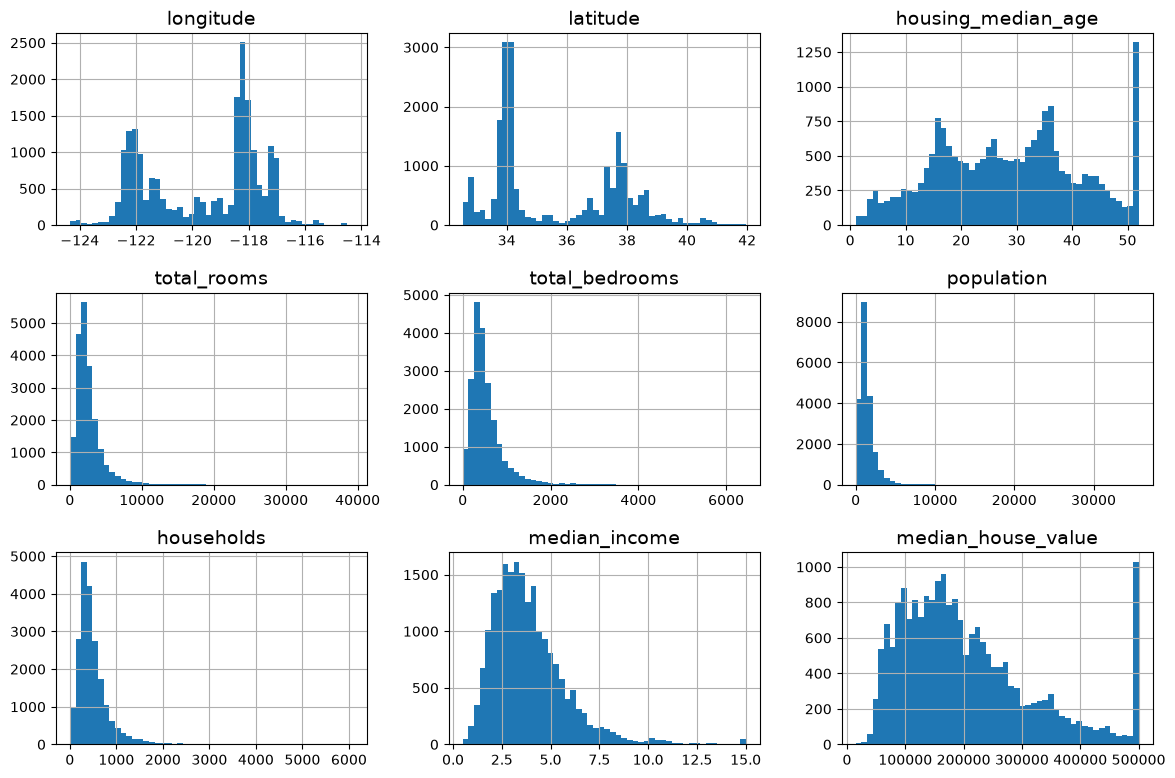

In [ ]:
import matplotlib.pyplot as plt

# extra code – the next 5 lines define the default font sizes
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

housing.hist(bins=50, figsize=(12, 8))
save_fig("attribute_histogram_plots")  # extra code
plt.show()

## Crear un conjunto de prueba (test set)

In [11]:
import numpy as np

def shuffle_and_split_data(data, test_ratio):
    shuffled_indices = np.random.permutation(len(data))
    test_set_size = int(len(data) * test_ratio)
    test_indices = shuffled_indices[:test_set_size]
    train_indices = shuffled_indices[test_set_size:]
    return data.iloc[train_indices], data.iloc[test_indices]

In [12]:
train_set, test_set = shuffle_and_split_data(housing, 0.2)
len(train_set)

16512

In [13]:
len(test_set)

4128

Para asegurarnos de que las salidas de este notebook sean siempre las mismas cada vez que lo ejecutemos, necesitamos fijar la semilla aleatoria (random seed):

In [14]:
np.random.seed(42)

Lamentablemente, esto no garantiza que este notebook produzca exactamente los mismos resultados que el libro, ya que existen otras posibles fuentes de variación. La más importante es el hecho de que los algoritmos se van ajustando con el tiempo a medida que las librerías evolucionan. Así que, por favor, tolerá algunas diferencias menores: idealmente, la mayoría de las salidas deberían coincidir, o al menos estar en el orden de magnitud correcto.

Nota: otra fuente de aleatoriedad es el orden de los conjuntos (sets) de Python: se basa en la función `hash()` de Python, que se "saltea" (salted) aleatoriamente cuando Python arranca (esto comenzó en Python 3.3, para prevenir ciertos ataques de denegación de servicio). Para eliminar esta aleatoriedad, la solución es fijar la variable de entorno `PYTHONHASHSEED` en `"0"` _antes_ de que Python siquiera arranque. No pasará nada si lo hacés después de eso. Por suerte, si estás ejecutando este notebook en Colab, la variable ya está configurada por vos.

In [15]:
from zlib import crc32

def is_id_in_test_set(identifier, test_ratio):
    return crc32(np.int64(identifier)) < test_ratio * 2**32

def split_data_with_id_hash(data, test_ratio, id_column):
    ids = data[id_column]
    in_test_set = ids.apply(lambda id_: is_id_in_test_set(id_, test_ratio))
    return data.loc[~in_test_set], data.loc[in_test_set]

In [16]:
housing_with_id = housing.reset_index()  # adds an `index` column
train_set, test_set = split_data_with_id_hash(housing_with_id, 0.2, "index")

In [17]:
housing_with_id["id"] = housing["longitude"] * 1000 + housing["latitude"]
train_set, test_set = split_data_with_id_hash(housing_with_id, 0.2, "id")

El que terminare usando es el siguiente

In [18]:
from sklearn.model_selection import train_test_split

train_set, test_set = train_test_split(housing, test_size=0.2, random_state=42)

In [19]:
test_set["total_bedrooms"].isnull().sum()

np.int64(44)

Para hallar la probabilidad de que una muestra aleatoria de 1.000 personas contenga menos del 48,5% de mujeres o más del 53,5% de mujeres, cuando la proporción de mujeres en la población es del 51,1%, utilizamos la [distribución binomial](https://en.wikipedia.org/wiki/Binomial_distribution). El método `cdf()` de la distribución binomial nos da la probabilidad de que el número de mujeres sea igual o menor que el valor dado.

In [20]:
# extra code – shows how to compute the 10.7% proba of getting a bad sample

from scipy.stats import binom

sample_size = 1000
ratio_female = 0.511
proba_too_small = binom(sample_size, ratio_female).cdf(485 - 1)
proba_too_large = 1 - binom(sample_size, ratio_female).cdf(535)
print(proba_too_small + proba_too_large)

0.10736798530930189


Si preferís las simulaciones por sobre la matemática, así es como podrías obtener aproximadamente el mismo resultado:

In [21]:
# extra code – shows another way to estimate the probability of bad sample

np.random.seed(42)

samples = (np.random.rand(100_000, sample_size) < ratio_female).sum(axis=1)
((samples < 485) | (samples > 535)).mean()

np.float64(0.1071)

In [22]:
housing["income_cat"] = pd.cut(housing["median_income"],
                               bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
                               labels=[1, 2, 3, 4, 5])

¿Qué significa cada parte? 

`housing["median_income"]`

Selecciona la columna que contiene la mediana de ingresos de cada distrito. En este dataset, los ingresos están expresados en unidades de aproximadamente 10.000 dólares.

`pd.cut()`

Es una función de Pandas que permite dividir valores numéricos en intervalos (bins) y asignar una categoría a cada intervalo.

`bins=[0., 1.5, 3.0, 4.5, 6., np.inf]`

Define los límites de los intervalos. np.inf representa el infinito positivo.

`labels=[1, 2, 3, 4, 5]`

Asigna una etiqueta a cada intervalo.

`housing["income_cat"] = ...`

Guarda las categorías resultantes en una nueva columna del DataFrame llamada income_cat.

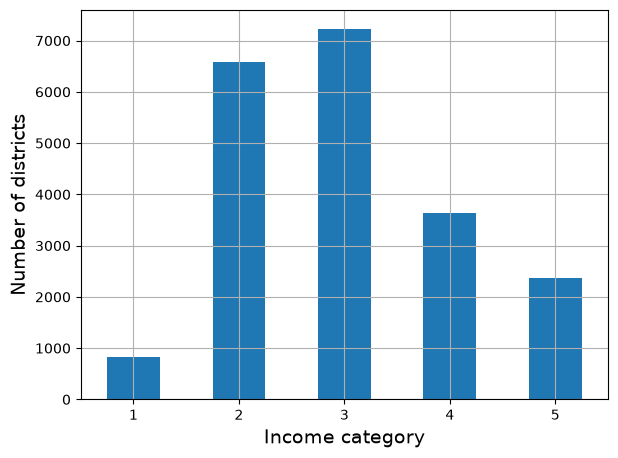

In [23]:
housing["income_cat"].value_counts().sort_index().plot.bar(rot=0, grid=True)
plt.xlabel("Income category")
plt.ylabel("Number of districts")
save_fig("housing_income_cat_bar_plot")  # extra code
plt.show()

El siguiente codigo genera 10 divisiones estratificadas del mismo conjunto de datos

In [24]:
from sklearn.model_selection import StratifiedShuffleSplit

splitter = StratifiedShuffleSplit(n_splits=10, test_size=0.2, random_state=42)
strat_splits = []
for train_index, test_index in splitter.split(housing, housing["income_cat"]):
    strat_train_set_n = housing.iloc[train_index]
    strat_test_set_n = housing.iloc[test_index]
    strat_splits.append([strat_train_set_n, strat_test_set_n])

In [25]:
strat_train_set, strat_test_set = strat_splits[0]

Es mucho más corto obtener una única división estratificada (stratified split):

La idea de estraficar el conjunto de prueba y test es no introducir sesgo muestral, es decir que los datos que estemos introduciendo no sean representativos de lo que yo quiero predecir posteriormente

In [26]:
strat_train_set, strat_test_set = train_test_split(
    housing, test_size=0.2, stratify=housing["income_cat"], random_state=42)

In [27]:
strat_test_set["income_cat"].value_counts() / len(strat_test_set)

income_cat
3    0.350533
2    0.318798
4    0.176357
5    0.114341
1    0.039971
Name: count, dtype: float64

In [28]:
# extra code – computes the data for Figure 2–10

def income_cat_proportions(data):
    return data["income_cat"].value_counts() / len(data)

train_set, test_set = train_test_split(housing, test_size=0.2, random_state=42)

compare_props = pd.DataFrame({
    "Overall %": income_cat_proportions(housing),
    "Stratified %": income_cat_proportions(strat_test_set),
    "Random %": income_cat_proportions(test_set),
}).sort_index()
compare_props.index.name = "Income Category"
compare_props["Strat. Error %"] = (compare_props["Stratified %"] /
                                   compare_props["Overall %"] - 1)
compare_props["Rand. Error %"] = (compare_props["Random %"] /
                                  compare_props["Overall %"] - 1)
(compare_props * 100).round(2)

,Overall %,Stratified %,Random %,Strat. Error %,Rand. Error %
Income Category,,,,,
1,3.98,4.00,4.24,0.36,6.45
2,31.88,31.88,30.74,-0.02,-3.59
3,35.06,35.05,34.52,-0.01,-1.53
4,17.63,17.64,18.41,0.03,4.42
5,11.44,11.43,12.09,-0.08,5.63


Aca se puede ver claramente que el conjunto generado mediante el muestreo estratificado tiene proporciones casi identicas a las del dataset original mientras que el de prueba generado sin estratificacion esta distorsionado

**🔎 Comparación de técnicas — Muestreo aleatorio vs. muestreo estratificado**

Ambos métodos dividen el dataset en entrenamiento y prueba, pero garantizan cosas distintas sobre la **representatividad** de esa división.

| | Muestreo aleatorio puro (`shuffle_and_split` / `train_test_split` sin `stratify`) | Muestreo estratificado (`StratifiedShuffleSplit` / `train_test_split(stratify=...)`) |
|---|---|---|
| **Qué hace** | Elige las filas de prueba al azar, de forma uniforme. | Divide los datos en estratos (grupos) y muestrea respetando la proporción de cada grupo. |
| **Representatividad** | Buena **en promedio**, pero con datasets chicos o categorías poco frecuentes puede sesgarse. | Garantiza que las proporciones de la variable de estratificación sean casi idénticas en train y test. |
| **Riesgo** | Sesgo de muestreo (sampling bias): el test puede sobre o subrepresentar un grupo. | Casi ninguno respecto de la variable elegida; requiere definir bien los estratos. |
| **Costo** | Trivial. | Igual de barato; solo hay que elegir la columna de estratificación. |

**¿Por qué en el notebook se usa el estratificado?** Porque `median_income` es un predictor muy fuerte de `median_house_value`. Si el test no refleja la distribución real de ingresos, el error medido no sería confiable. Por eso se crea `income_cat` (discretizando el ingreso con `pd.cut`) y se estratifica sobre esa categoría.

**💼 ¿Qué utilizaría en un proyecto real?**

1. **Elección recomendada:** `train_test_split(..., stratify=columna)` cuando exista una variable (o categoría derivada) con fuerte impacto sobre el objetivo y cuyo balance quiera preservar; muestreo aleatorio simple cuando el dataset es grande y homogéneo.
2. **Uso en la industria:** el aleatorio simple es el *default* para datasets grandes. El estratificado es estándar en **clasificación con clases desbalanceadas** (fraude, churn, diagnóstico médico) y cuando una variable numérica clave está sesgada.
3. **Criterios de decisión:** tamaño del dataset (cuanto más chico, más importa estratificar), presencia de categorías raras, y si una variable domina la predicción.
4. **Ejemplo laboral:** en un modelo de precios inmobiliarios, estratificar por rango de ingresos o por región evita que el test quede lleno de barrios caros y el modelo parezca mejor de lo que es.
5. **Buenas prácticas:** definir el split **una sola vez y lo antes posible**, fijar `random_state` para reproducibilidad, y no volver a mirar el test hasta la evaluación final.
6. **Qué debería recordar:** por defecto estratifico cuando hay desbalance o una variable crítica; en datasets masivos y homogéneos el aleatorio simple alcanza.

Como ya analizamos, estratificamos bien la muestra y generamos los conjuntos de entrenamiento y prueba , la columna nueva que generamos de categoria de ingresos podemos quitarla y seguir con el dataset en su estado original

**⚠️ Error común — No reutilizar el mismo test set entre ejecuciones**

Un problema típico de dividir con `np.random.permutation` sin control es que, cada vez que ejecutás el programa, se genera **un test set distinto**. Con el tiempo, el modelo termina "viendo" todo el dataset, lo que contamina la evaluación (una forma sutil de *data leakage*).

Soluciones que aparecen en el capítulo, de menor a mayor robustez:
- Fijar `np.random.seed(42)` → reproducible, pero se rompe si cambia el dataset.
- Usar un **hash de un identificador estable** de cada fila (`crc32` del `id`) → la pertenencia al test depende solo del id, no del orden ni del tamaño del dataset.
- `train_test_split(random_state=42)` → la opción práctica estándar de Scikit-Learn.

In [29]:
for set_ in (strat_train_set, strat_test_set):
    set_.drop("income_cat", axis=1, inplace=True)

# Discover and Visualize the Data to Gain Insights

In [30]:
housing = strat_train_set.copy()

### ¿Por qué usamos copia independiente del conjunto de entrenamiento?

Creamos una **copia independiente del conjunto de entrenamiento** para explorar y modificar los datos sin alterar los originales.

- **Con `.copy()`**: los cambios en `housing` no afectan a `strat_train_set`.
- **Sin `.copy()`**: ambas variables apuntan al mismo DataFrame, por lo que las modificaciones pueden afectar a ambas.

**Objetivo:** preservar los datos originales de entrenamiento mientras realizamos el análisis exploratorio (EDA).

## Visualizar datos geográficos

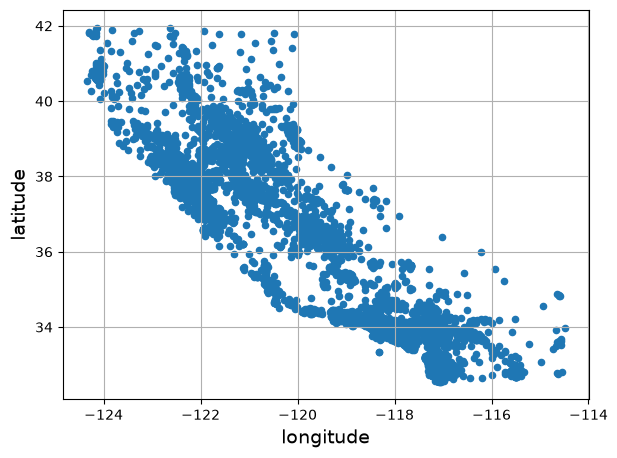

In [31]:
housing.plot(kind="scatter", x="longitude", y="latitude", grid=True)
save_fig("bad_visualization_plot")  # extra code
plt.show()

Utilizo alpha=0.2 para resaltar las zonas de alta densidad. Es decir, que hay muchos puntos.

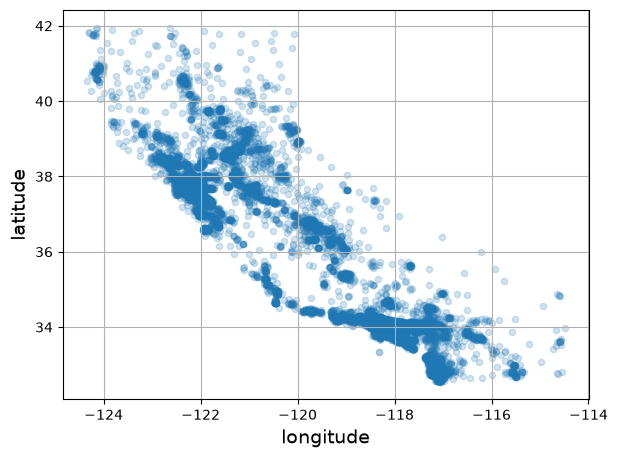

In [32]:
housing.plot(kind="scatter", x="longitude", y="latitude", grid=True, alpha=0.2)
save_fig("better_visualization_plot")  # extra code
plt.show()

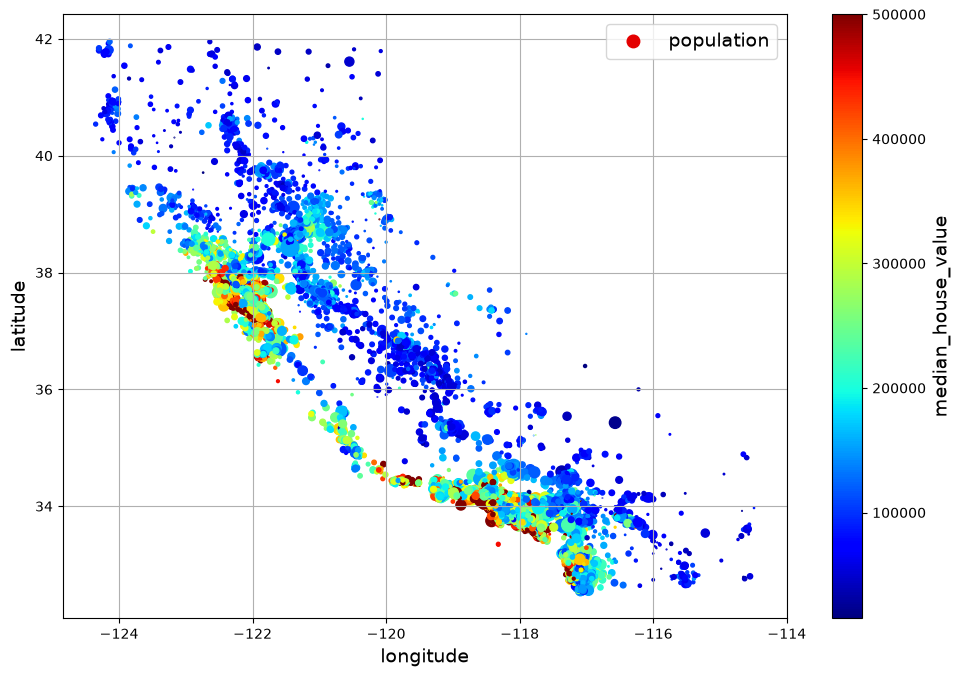

In [33]:
housing.plot(kind="scatter", x="longitude", y="latitude", grid=True,
             s=housing["population"] / 100, label="population",
             c="median_house_value", cmap="jet", colorbar=True,
             legend=True, sharex=False, figsize=(10, 7))
save_fig("housing_prices_scatterplot")  # extra code
plt.show()
# kind="scatter": Genera un gráfico de dispersión.
# x="longitude": Utiliza la longitud geográfica en el eje X.
# y="latitude": Utiliza la latitud geográfica en el eje Y.
# grid=True: Muestra una cuadrícula en el gráfico.
# s=housing["population"] / 100: Define el tamaño de los puntos según la población.
# label="population": Asigna una etiqueta para la leyenda.
# c="median_house_value": Colorea cada punto según el precio mediano de las viviendas.
# cmap="jet": Utiliza una escala de colores de azul (valores bajos) a rojo (valores altos).
# colorbar=True: Muestra una barra lateral con la escala de colores y precios.
# legend=True: Muestra la leyenda del gráfico.
# sharex=False: Evita compartir el eje X con otros gráficos.
# figsize=(10, 7): Define el tamaño del gráfico (ancho, alto) en pulgadas.
# save_fig(): Guarda el gráfico en un archivo.
# plt.show(): Muestra el gráfico en pantalla.

El argumento `sharex=False` corrige un bug de visualización: sin él, los valores y la etiqueta del eje x no se muestran (ver: https://github.com/pandas-dev/pandas/issues/10611).

La siguiente celda genera la primera figura del capítulo (este código no está en el libro). Es simplemente una versión embellecida de la figura anterior, con una imagen de California agregada de fondo, nombres de etiquetas más lindos y sin la grilla.

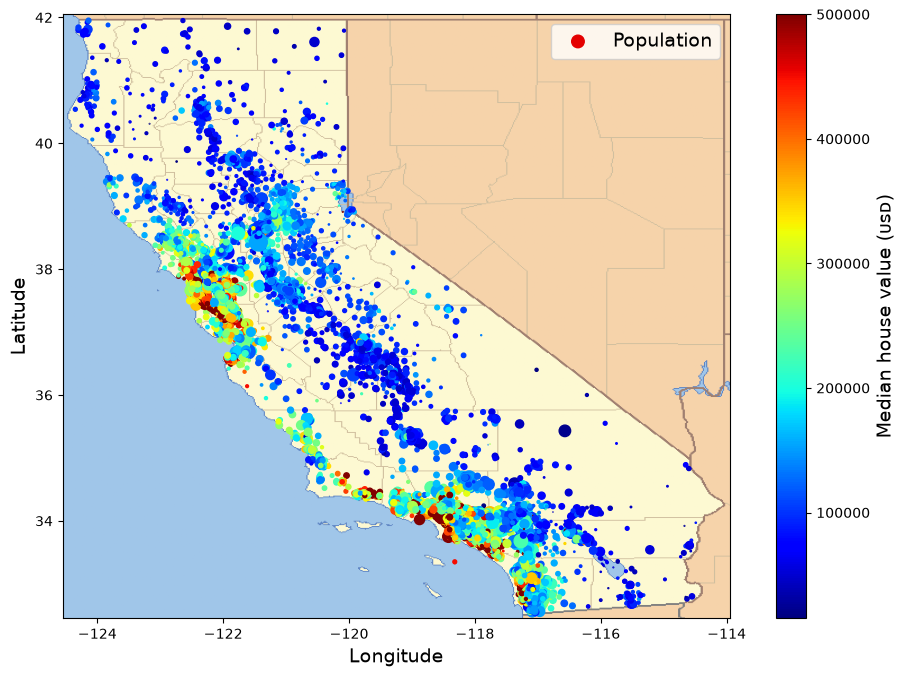

In [34]:
# extra code – this cell generates the first figure in the chapter

# Download the California image
filename = "california.png"
if not (IMAGES_PATH / filename).is_file():
    homl3_root = "https://github.com/ageron/handson-ml3/raw/main/"
    url = homl3_root + "images/end_to_end_project/" + filename
    print("Downloading", filename)
    urllib.request.urlretrieve(url, IMAGES_PATH / filename)

housing_renamed = housing.rename(columns={
    "latitude": "Latitude", "longitude": "Longitude",
    "population": "Population",
    "median_house_value": "Median house value (ᴜsᴅ)"})
housing_renamed.plot(
             kind="scatter", x="Longitude", y="Latitude",
             s=housing_renamed["Population"] / 100, label="Population",
             c="Median house value (ᴜsᴅ)", cmap="jet", colorbar=True,
             legend=True, sharex=False, figsize=(10, 7))

california_img = plt.imread(IMAGES_PATH / filename)
axis = -124.55, -113.95, 32.45, 42.05
plt.axis(axis)
plt.imshow(california_img, extent=axis)

save_fig("california_housing_prices_plot")
plt.show()

## Buscar correlaciones

Nota: desde Pandas 2.0.0, el argumento `numeric_only` toma por defecto el valor `False`, por lo que debemos establecerlo explícitamente en `True` para evitar un error.

Correlacion estandar tambien llamado coeficiente R de Pearson. Va de -1 a 1. Cuando se acerca a 1 significa que hay una correlacion positiva fuerte, cuando es cero no hay correlacion y cuando se acerca a -1 hay una correlacion negativa fuerte
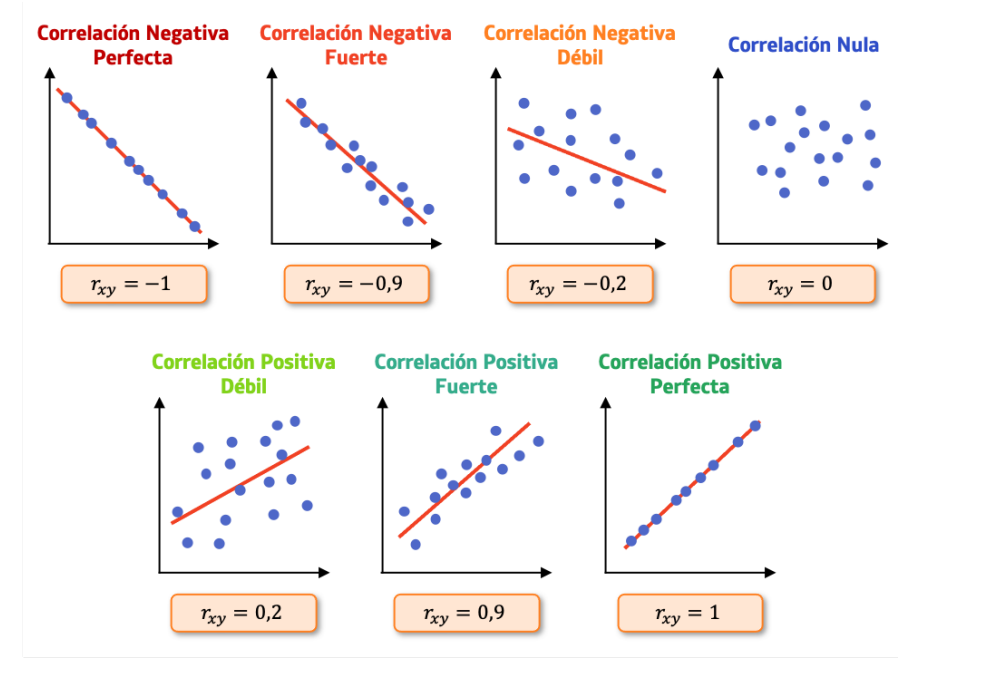

**📘 Explicación adicional — El coeficiente de correlación de Pearson**

El coeficiente $r$ de Pearson mide la fuerza y el sentido de la relación **lineal** entre dos variables:

$$r = \frac{\sum_{i}(x_i-\bar{x})(y_i-\bar{y})}{\sqrt{\sum_{i}(x_i-\bar{x})^2}\;\sqrt{\sum_{i}(y_i-\bar{y})^2}}$$

- El **numerador** es la covarianza (sin normalizar): es positivo cuando $x$ e $y$ tienden a estar por encima de su media a la vez.
- El **denominador** normaliza por las desviaciones de cada variable, dejando $r$ acotado en $[-1, 1]$.

| Valor de $r$ | Interpretación |
|---|---|
| $\approx +1$ | correlación lineal positiva fuerte |
| $\approx 0$ | sin correlación **lineal** |
| $\approx -1$ | correlación lineal negativa fuerte |

**Limitación clave:** $r$ solo capta relaciones *lineales*. Dos variables pueden tener una relación fuerte pero no lineal (p. ej. en forma de U) y aun así dar $r \approx 0$. Por eso, en el notebook, además de `corr()` se usa `scatter_matrix` para ver visualmente la forma real de las relaciones.

In [35]:
corr_matrix = housing.corr(numeric_only=True) # Aramos la matriz de correlaciones (Que tan relacionados estan los atributos entre si)
corr_matrix

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924213,-0.102937,0.044558,0.068210,0.104236,0.054261,-0.016542,-0.050859
latitude,-0.924213,1.000000,0.005692,-0.036753,-0.066391,-0.115677,-0.071604,-0.078137,-0.139584
housing_median_age,-0.102937,0.005692,1.000000,-0.361710,-0.317978,-0.301906,-0.300075,-0.127043,0.102175
total_rooms,0.044558,-0.036753,-0.361710,1.000000,0.930076,0.863967,0.916143,0.197720,0.137455
total_bedrooms,0.068210,-0.066391,-0.317978,0.930076,1.000000,0.886200,0.978822,-0.006038,0.054635
population,0.104236,-0.115677,-0.301906,0.863967,0.886200,1.000000,0.916237,0.004282,-0.020153
households,0.054261,-0.071604,-0.300075,0.916143,0.978822,0.916237,1.000000,0.013637,0.071426
median_income,-0.016542,-0.078137,-0.127043,0.197720,-0.006038,0.004282,0.013637,1.000000,0.688380
median_house_value,-0.050859,-0.139584,0.102175,0.137455,0.054635,-0.020153,0.071426,0.688380,1.000000


In [36]:
corr_matrix["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688380
total_rooms           0.137455
housing_median_age    0.102175
households            0.071426
total_bedrooms        0.054635
population           -0.020153
longitude            -0.050859
latitude             -0.139584
Name: median_house_value, dtype: float64

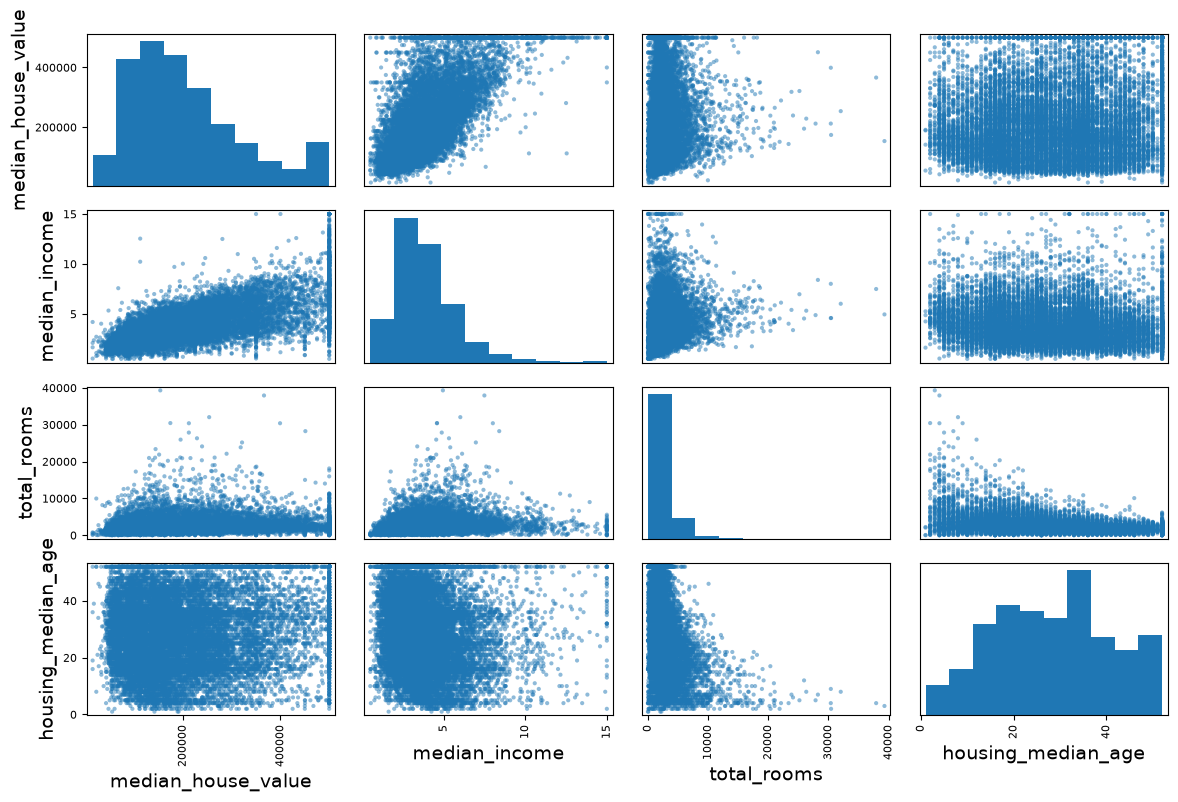

In [37]:
from pandas.plotting import scatter_matrix

attributes = ["median_house_value", "median_income", "total_rooms",
              "housing_median_age"]
scatter_matrix(housing[attributes], figsize=(12, 8))
save_fig("scatter_matrix_plot")  # extra code
plt.show()

### La idea de estos graficos es visualizar las correlaciones
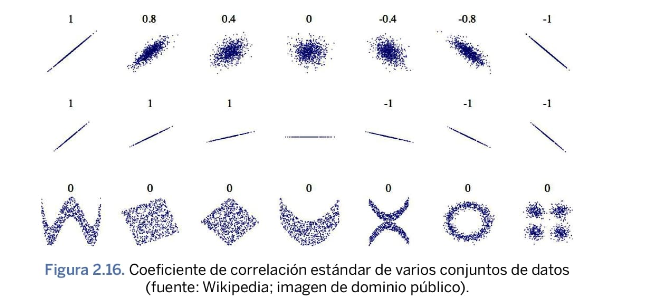

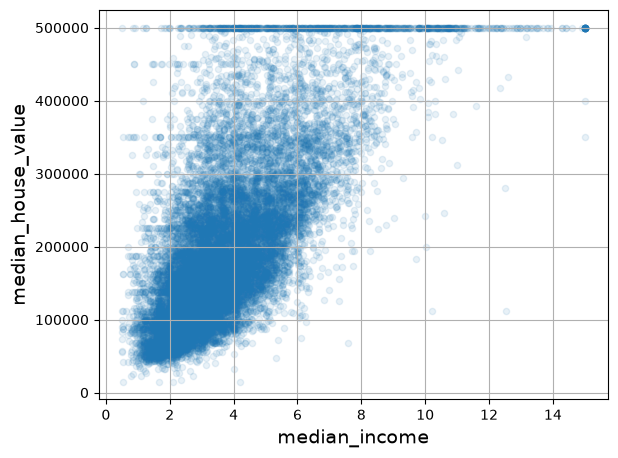

In [38]:
housing.plot(kind="scatter", x="median_income", y="median_house_value",
             alpha=0.1, grid=True)
save_fig("income_vs_house_value_scatterplot")  # extra code
plt.show()

**⚠️ Error común — Confundir correlación con causalidad**

Que `median_income` correlacione fuerte con `median_house_value` **no significa** que el ingreso *cause* el precio por sí solo. La correlación es una medida estadística de co-variación; la causalidad requiere un argumento adicional (experimentos, teoría del dominio, control de variables de confusión).

En ML esto importa por dos motivos:
- Una variable muy correlacionada puede ser un **buen predictor** aunque no sea una causa (y eso es suficiente para predecir).
- Pero no podemos concluir que "subir el ingreso del barrio subirá el precio": podría haber una tercera variable (ubicación, servicios) que mueva a ambas.

Regla práctica: usá la correlación para **seleccionar features y predecir**, no para afirmar relaciones de causa-efecto.

## Experimentar con combinaciones de atributos

In [39]:
housing["rooms_per_house"] = housing["total_rooms"] / housing["households"]
housing["bedrooms_ratio"] = housing["total_bedrooms"] / housing["total_rooms"]
housing["people_per_house"] = housing["population"] / housing["households"]

In [40]:
corr_matrix = housing.corr(numeric_only=True)
corr_matrix["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688380
rooms_per_house       0.143663
total_rooms           0.137455
housing_median_age    0.102175
households            0.071426
total_bedrooms        0.054635
population           -0.020153
people_per_house     -0.038224
longitude            -0.050859
latitude             -0.139584
bedrooms_ratio       -0.256397
Name: median_house_value, dtype: float64

# Preparar los datos para los algoritmos de Machine Learning

Volvamos al conjunto de entrenamiento original y separemos la variable objetivo (notá que `strat_train_set.drop()` crea una copia de `strat_train_set` sin esa columna, no modifica realmente `strat_train_set` en sí, a menos que le pases `inplace=True`):

In [41]:
housing = strat_train_set.drop("median_house_value", axis=1)
housing_labels = strat_train_set["median_house_value"].copy()
housing_labels

13096    458300.0
14973    483800.0
3785     101700.0
14689     96100.0
20507    361800.0
           ...   
14207    500001.0
13105     88800.0
19301    148800.0
19121    500001.0
19888    233300.0
Name: median_house_value, Length: 16512, dtype: float64

Ahora como vamos a preparar los datos para luego pasarlos por los algoritmos de machine learning. Volvemos a hacer una copia del dataset pero quitando la variable objetivo (median_house_value) para no aplicar transformaciones a los que queremos predecir. Por eso por un lado guardamos en housing el conjunto estratificado de entrenamiento sin la variable objetivo y esta ultima la guardamos en otra variable.

## Limpieza de datos (Data Cleaning)

Ahora empezamos con la limpieza de los datos, como al total de habitaciones le faltan datos, tenemos 3 opciones para solucionarlo:
1. Quitar esos registros que tienen valores NaN
2. Quitar toda la columna/atributo
3. Imputarlos. Es decir, establecer algun valor para esos valores que faltan (cero, la media, la mediana, moda, etc)

En el libro se enumeran 3 opciones para manejar los valores NaN:

```python
housing.dropna(subset=["total_bedrooms"], inplace=True)    # opción 1

housing.drop("total_bedrooms", axis=1)       # opción 2

median = housing["total_bedrooms"].median()  # opción 3
housing["total_bedrooms"].fillna(median, inplace=True)
```

Para cada opción, crearemos una copia de `housing` y trabajaremos sobre esa copia para no romper `housing`. También mostraremos la salida de cada opción, pero filtrando las filas que originalmente contenían un valor NaN.

In [42]:
null_rows_idx = housing.isnull().any(axis=1)
housing.loc[null_rows_idx].head()
# isnull(): Detecta valores faltantes (NaN) y devuelve True o False.
# any(): Verifica si existe al menos un True.
# axis=1: Comprueba los valores a lo largo de las columnas de cada fila.
# axis=0: Comprueba los valores a lo largo de las filas de cada columna.
# null_rows_idx: Guarda una máscara booleana que identifica filas con datos faltantes.
# loc[null_rows_idx]: Selecciona las filas que tienen al menos un valor nulo.
# head(): Muestra las primeras 5 filas del resultado.

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
14452,-120.67,40.50,15.0,5343.0,NaN,2503.0,902.0,3.5962,INLAND
18217,-117.96,34.03,35.0,2093.0,NaN,1755.0,403.0,3.4115,<1H OCEAN
11889,-118.05,34.04,33.0,1348.0,NaN,1098.0,257.0,4.2917,<1H OCEAN
20325,-118.88,34.17,15.0,4260.0,NaN,1701.0,669.0,5.1033,<1H OCEAN
14360,-117.87,33.62,8.0,1266.0,NaN,375.0,183.0,9.8020,<1H OCEAN


### Opcion 1

In [43]:
housing_option1 = housing.copy()

housing_option1.dropna(subset=["total_bedrooms"], inplace=True)  # option 1

housing_option1.loc[null_rows_idx].head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity


### Opcion 2

In [44]:
housing_option2 = housing.copy()

housing_option2.drop("total_bedrooms", axis=1, inplace=True)  # 

housing_option2.loc[null_rows_idx].head()
# axis=0: Indica el eje de las filas. En drop(), elimina filas.
# axis=1: Indica el eje de las columnas. En drop(), elimina columnas.
# inplace=True: Modifica directamente el DataFrame original.
# inplace=False: Devuelve un nuevo DataFrame sin modificar el original.

,longitude,latitude,housing_median_age,total_rooms,population,households,median_income,ocean_proximity
14452,-120.67,40.50,15.0,5343.0,2503.0,902.0,3.5962,INLAND
18217,-117.96,34.03,35.0,2093.0,1755.0,403.0,3.4115,<1H OCEAN
11889,-118.05,34.04,33.0,1348.0,1098.0,257.0,4.2917,<1H OCEAN
20325,-118.88,34.17,15.0,4260.0,1701.0,669.0,5.1033,<1H OCEAN
14360,-117.87,33.62,8.0,1266.0,375.0,183.0,9.8020,<1H OCEAN


### Opcion 3

In [45]:
housing_option3 = housing.copy()

median = housing["total_bedrooms"].median()
housing_option3["total_bedrooms"].fillna(median, inplace=True)  # option 3

housing_option3.loc[null_rows_idx].head()

C:\Users\famil\AppData\Local\Temp\ipykernel_12044\3218827148.py:4: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  housing_option3["total_bedrooms"].fillna(median, inplace=True)  # option 3


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
14452,-120.67,40.50,15.0,5343.0,NaN,2503.0,902.0,3.5962,INLAND
18217,-117.96,34.03,35.0,2093.0,NaN,1755.0,403.0,3.4115,<1H OCEAN
11889,-118.05,34.04,33.0,1348.0,NaN,1098.0,257.0,4.2917,<1H OCEAN
20325,-118.88,34.17,15.0,4260.0,NaN,1701.0,669.0,5.1033,<1H OCEAN
14360,-117.87,33.62,8.0,1266.0,NaN,375.0,183.0,9.8020,<1H OCEAN


In [46]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

**📘 Explicación adicional — `SimpleImputer` y el ciclo `fit` / `transform`**

1. **¿Qué hacemos?** Rellenamos (imputamos) los valores faltantes de los atributos numéricos. `total_bedrooms` tiene NaN en algunos distritos y la mayoría de los algoritmos de Scikit-Learn no aceptan NaN.

2. **¿Por qué?** Descartar filas (opción 1) pierde información; descartar la columna (opción 2) elimina una variable potencialmente útil. La imputación conserva todas las filas y columnas.

3. **¿Cómo funciona?** `SimpleImputer(strategy="median")`:
   - `imputer.fit(housing_num)` → **aprende** y guarda la mediana de cada columna en `imputer.statistics_`. Esto es lo que verifica la celda que compara con `housing_num.median().values`.
   - `imputer.transform(X)` → **aplica** esas medianas aprendidas, reemplazando los NaN.
   - `fit_transform` hace ambos pasos de una sola vez (se usa solo en entrenamiento).

4. **Parámetros importantes:** `strategy` puede ser `"mean"`, `"median"`, `"most_frequent"` (moda, sirve también para categóricas) o `"constant"` (`fill_value`).

5. **Resultado esperado:** una matriz sin NaN, con la misma forma que la entrada.

6. **¿Cuándo se usa?** Prácticamente en todo pipeline tabular real, porque los datos del mundo real casi siempre tienen huecos.

**🔎 Comparación de técnicas — Media vs. mediana para imputar**

| | Media (`strategy="mean"`) | Mediana (`strategy="median"`) |
|---|---|---|
| **Qué calcula** | Promedio aritmético de la columna. | Valor central (percentil 50). |
| **Sensibilidad a outliers** | Alta: unos pocos valores extremos la desplazan. | Baja: es un estadístico robusto. |
| **Distribución ideal** | Variables aproximadamente simétricas/normales. | Variables sesgadas (skewed) o con outliers. |

**¿Por qué el notebook usa la mediana?** Muchas variables de este dataset (ingresos, cantidad de habitaciones, población) están sesgadas a la derecha y tienen valores extremos. La mediana evita que esos extremos distorsionen el valor imputado.

**🔎 Comparación — `SimpleImputer` vs. `IterativeImputer`** *(ampliación, no está en el notebook)*

| | `SimpleImputer` | `IterativeImputer` |
|---|---|---|
| **Idea** | Rellena cada columna con un estadístico fijo (media/mediana/moda). | Modela cada columna con faltantes como función (regresión) del resto de las columnas, iterando. |
| **Usa relaciones entre variables** | No. | Sí. |
| **Costo y complejidad** | Muy bajo, determinista. | Mayor; es experimental en Scikit-Learn (`enable_iterative_imputer`). |
| **Cuándo** | *Baseline* y producción simple; pocos faltantes. | Cuando las variables están correlacionadas y la imputación simple degrada el modelo. |

**💼 ¿Qué utilizaría en un proyecto real?** Arranco siempre con `SimpleImputer(strategy="median")` como *baseline* dentro de un `Pipeline` (reproducible y sin leakage). Solo paso a `IterativeImputer` o `KNNImputer` si mido una mejora real en validación que justifique el costo extra de cómputo y mantenimiento. Lo esencial: **el imputador se ajusta (`fit`) solo con el train** y luego se aplica (`transform`) al test, nunca al revés.

Separamos los atributos numéricos para poder usar la estrategia `"median"` (ya que no puede calcularse sobre atributos de texto como `ocean_proximity`):

In [47]:
housing_num = housing.select_dtypes(include=[np.number])

In [48]:
imputer.fit(housing_num)

,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['longitude','latitude','housing_median_age',...,'population','households', 'median_income']"
indicator_ indicator_: :class:`~sklearn.impute.MissingIndicator`Indicator used to add binary indicators for missing values.`None` if `add_indicator=False`.,NoneType,None
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
"statistics_ statistics_: array of shape (n_features,)The imputation fill value for each feature.Computing statistics can result in `np.nan` values.During :meth:`transform`, features corresponding to `np.nan`statistics will be discarded.","ndarray[float64](8,)","[-118.51, 34.26, 29. ,...,1167. , 408. , 3.54]"


In [49]:
imputer.statistics_

array([-118.51  ,   34.26  ,   29.    , 2125.    ,  434.    , 1167.    ,
        408.    ,    3.5385])

Verificamos que esto sea lo mismo que calcular manualmente la mediana de cada atributo:

In [50]:
housing_num.median().values

array([-118.51  ,   34.26  ,   29.    , 2125.    ,  434.    , 1167.    ,
        408.    ,    3.5385])

Transformamos el conjunto de entrenamiento:

In [51]:
X = imputer.transform(housing_num)
X

array([[-1.2242e+02,  3.7800e+01,  5.2000e+01, ...,  1.5760e+03,
         1.0340e+03,  2.0987e+00],
       [-1.1838e+02,  3.4140e+01,  4.0000e+01, ...,  6.6600e+02,
         3.5700e+02,  6.0876e+00],
       [-1.2198e+02,  3.8360e+01,  3.3000e+01, ...,  5.6200e+02,
         2.0300e+02,  2.4330e+00],
       ...,
       [-1.1706e+02,  3.2590e+01,  1.3000e+01, ...,  2.8140e+03,
         7.6000e+02,  4.0616e+00],
       [-1.1840e+02,  3.4060e+01,  3.7000e+01, ...,  1.7250e+03,
         8.3800e+02,  4.1455e+00],
       [-1.2241e+02,  3.7660e+01,  4.4000e+01, ...,  6.8200e+02,
         2.1200e+02,  3.2833e+00]], shape=(16512, 8))

In [52]:
imputer.feature_names_in_

array(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income'],
      dtype=object)

In [53]:
housing_tr = pd.DataFrame(X, columns=housing_num.columns,
                          index=housing_num.index)
housing_tr

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
13096,-122.42,37.80,52.0,3321.0,1115.0,1576.0,1034.0,2.0987
14973,-118.38,34.14,40.0,1965.0,354.0,666.0,357.0,6.0876
3785,-121.98,38.36,33.0,1083.0,217.0,562.0,203.0,2.4330
14689,-117.11,33.75,17.0,4174.0,851.0,1845.0,780.0,2.2618
20507,-118.15,33.77,36.0,4366.0,1211.0,1912.0,1172.0,3.5292
...,...,...,...,...,...,...,...,...
14207,-118.40,33.86,41.0,2237.0,597.0,938.0,523.0,4.7105
13105,-119.31,36.32,23.0,2945.0,592.0,1419.0,532.0,2.5733
19301,-117.06,32.59,13.0,3920.0,775.0,2814.0,760.0,4.0616
19121,-118.40,34.06,37.0,3781.0,873.0,1725.0,838.0,4.1455


In [54]:
housing_tr.loc[null_rows_idx].head()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
14452,-120.67,40.50,15.0,5343.0,434.0,2503.0,902.0,3.5962
18217,-117.96,34.03,35.0,2093.0,434.0,1755.0,403.0,3.4115
11889,-118.05,34.04,33.0,1348.0,434.0,1098.0,257.0,4.2917
20325,-118.88,34.17,15.0,4260.0,434.0,1701.0,669.0,5.1033
14360,-117.87,33.62,8.0,1266.0,434.0,375.0,183.0,9.8020


In [55]:
imputer.strategy

'median'

In [56]:
housing_tr = pd.DataFrame(X, columns=housing_num.columns,
                          index=housing_num.index)

In [57]:
housing_tr.loc[null_rows_idx].head()  # not shown in the book

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
14452,-120.67,40.50,15.0,5343.0,434.0,2503.0,902.0,3.5962
18217,-117.96,34.03,35.0,2093.0,434.0,1755.0,403.0,3.4115
11889,-118.05,34.04,33.0,1348.0,434.0,1098.0,257.0,4.2917
20325,-118.88,34.17,15.0,4260.0,434.0,1701.0,669.0,5.1033
14360,-117.87,33.62,8.0,1266.0,434.0,375.0,183.0,9.8020


In [58]:
#from sklearn import set_config
#
# set_config(transform_output="pandas")  # scikit-learn >= 1.2

Ahora eliminemos algunos valores atípicos (outliers):

## Detección de valores atípicos (Outliers) con Isolation Forest

### ¿Qué es un outlier?

Un **outlier** es una observación que presenta características muy diferentes a las del resto de los datos. Puede representar un error, un caso excepcional o un valor válido poco frecuente.

### ¿Qué es Isolation Forest?

**Isolation Forest** es un algoritmo de Machine Learning **no supervisado** utilizado para detectar anomalías o valores atípicos.

Su funcionamiento consiste en construir árboles que dividen aleatoriamente los datos para aislar las observaciones.

- **Observaciones normales:** generalmente necesitan más divisiones para ser aisladas.
- **Outliers:** suelen necesitar menos divisiones porque presentan características poco comunes.

In [59]:
from sklearn.ensemble import IsolationForest

isolation_forest = IsolationForest(random_state=42)
outlier_pred = isolation_forest.fit_predict(X)
# IsolationForest: Algoritmo no supervisado para detectar valores atípicos.
# random_state=42: Fija la semilla aleatoria para obtener resultados reproducibles.
# fit_predict(X): Ajusta el modelo y clasifica cada observación.
# X: Matriz de características utilizadas para detectar anomalías.
# outlier_pred: Array que almacena las predicciones del algoritmo.
# 1: Observación considerada normal (inlier).
# -1: Observación considerada atípica (outlier).
# outlier_pred == 1: Máscara booleana para conservar observaciones normales.
# iloc[]: Selecciona filas por posición utilizando esa máscara.
# housing_labels: Se filtra igual que housing para mantener la correspondencia.

In [60]:
outlier_pred

array([-1,  1,  1, ...,  1,  1,  1], shape=(16512,))

-1 ATIPICO, 1 TIPICO. En este caso, el primer valor seria atipico

Si quisieras eliminar los outliers, ejecutarías el siguiente código:

In [61]:
housing = housing.iloc[outlier_pred == 1]
housing_labels = housing_labels.iloc[outlier_pred == 1]

## Manejo de atributos de texto y categóricos

Ahora preprocesemos la característica categórica de entrada, `ocean_proximity`:

In [62]:
housing_cat = housing[["ocean_proximity"]]
housing_cat.head(8)

,ocean_proximity
14973,<1H OCEAN
3785,INLAND
14689,INLAND
20507,NEAR OCEAN
1286,INLAND
18078,<1H OCEAN
4396,NEAR BAY
18031,<1H OCEAN


La idea ahora es transformar estos valores categoricos a valores numericos ya que los algoritmos de machine learning prefieren trabajar con numeros. Por eso vamos a utilzar lo siguiente:

In [63]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_encoder = OrdinalEncoder()
housing_cat_encoded = ordinal_encoder.fit_transform(housing_cat)

In [64]:
housing_cat_encoded

array([[0.],
       [1.],
       [1.],
       ...,
       [4.],
       [0.],
       [4.]], shape=(14448, 1))

In [65]:
ordinal_encoder.categories_

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
       dtype=object)]

**🔎 Comparación de técnicas — `OrdinalEncoder` vs. `OneHotEncoder`**

Las dos convierten texto en números, pero representan las categorías de forma radicalmente distinta.

| | `OrdinalEncoder` | `OneHotEncoder` |
|---|---|---|
| **Salida** | Un entero por categoría (0, 1, 2, ...). | Un vector binario (una columna por categoría). |
| **Supone orden** | Sí: implica que 2 > 1 > 0. | No: todas las categorías son equidistantes. |
| **Dimensionalidad** | 1 sola columna. | Tantas columnas como categorías. |
| **Ideal para** | Variables **ordinales** reales (bajo < medio < alto). | Variables **nominales** sin orden (como `ocean_proximity`). |

**¿Por qué importa?** Si codificás con enteros una variable sin orden, el modelo asumirá relaciones falsas: que `INLAND`(1) está "entre" `<1H OCEAN`(0) e `ISLAND`(2), lo cual no tiene sentido. Modelos lineales y basados en distancia son especialmente sensibles a esto; los árboles lo toleran mejor pero igual puede confundirlos.

**⚠️ Error común — Usar codificación ordinal cuando no hay orden real**

`ocean_proximity` es **nominal**: `NEAR BAY`, `INLAND`, `ISLAND`, etc. no tienen un orden natural. Aplicarle `OrdinalEncoder` le mete al modelo una suposición de magnitud inexistente. Para variables nominales, `OneHotEncoder` (o embeddings en deep learning) es la opción correcta. Reservá `OrdinalEncoder` para categorías genuinamente ordenadas (p. ej. `"primaria" < "secundaria" < "universitaria"`), idealmente pasándole el orden con el parámetro `categories`.

**💼 ¿Qué utilizaría en un proyecto real?**

1. **Elección recomendada:** `OneHotEncoder` para variables nominales de **baja cardinalidad** (pocas categorías, como acá). Para variables ordinales, `OrdinalEncoder` con el orden explícito.
2. **Uso en la industria:** One-Hot es el estándar en modelos lineales, SVM y redes. Con **árboles/boosting** (RandomForest, XGBoost, LightGBM) y variables de **alta cardinalidad** (miles de categorías) se usan alternativas: *target/mean encoding*, *hashing*, o el soporte categórico nativo de LightGBM/CatBoost.
3. **Criterios de decisión:** cardinalidad (One-Hot explota en columnas si hay miles de categorías), tipo de modelo, e interpretabilidad.
4. **Ejemplo laboral:** para predecir precios de propiedades, `tipo_de_propiedad` (casa/depto/PH) → One-Hot; `barrio` con 2.000 valores → target encoding o embeddings.
5. **Buenas prácticas:** siempre dentro de un `ColumnTransformer`, con `handle_unknown="ignore"` para no romper en producción ante categorías nuevas, y haciendo `fit` solo en train.
6. **Qué debería recordar:** One-Hot por defecto para nominales de baja cardinalidad; si la cardinalidad es alta o uso boosting, evalúo encoders más compactos.

In [66]:
from sklearn.preprocessing import OneHotEncoder

cat_encoder = OneHotEncoder()
housing_cat_1hot = cat_encoder.fit_transform(housing_cat)

In [67]:
housing_cat_1hot

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 14448 stored elements and shape (14448, 5)>

Por defecto, la clase `OneHotEncoder` devuelve un array disperso (sparse array), pero podemos convertirlo a un array denso (dense array) si es necesario, llamando al método `toarray()`:

In [68]:
housing_cat_1hot.toarray()

array([[1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       ...,
       [0., 0., 0., 0., 1.],
       [1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1.]], shape=(14448, 5))

Alternativamente, podés establecer `sparse_output=False` al crear el `OneHotEncoder` (nota: el hiperparámetro `sparse` fue renombrado a `sparse_output` en Scikit-Learn 1.2):

In [69]:
cat_encoder = OneHotEncoder(sparse_output=False)
housing_cat_1hot = cat_encoder.fit_transform(housing_cat)
housing_cat_1hot

array([[1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       ...,
       [0., 0., 0., 0., 1.],
       [1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1.]], shape=(14448, 5))

In [70]:
cat_encoder.categories_

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
       dtype=object)]

In [71]:
df_test = pd.DataFrame({"ocean_proximity": ["INLAND", "NEAR BAY"]})
pd.get_dummies(df_test)

,ocean_proximity_INLAND,ocean_proximity_NEAR BAY
0,True,False
1,False,True


In [72]:
cat_encoder.transform(df_test)

array([[0., 1., 0., 0., 0.],
       [0., 0., 0., 1., 0.]])

Tambien tenemos la funcion get_dummies() que hace lo mismo que la one-hot pero la ventaja que tiene one-hot y es por eso que la utilizamos es que recuerda en que categorias se ha entrenado. 

In [73]:
df_test_unknown = pd.DataFrame({"ocean_proximity": ["<2H OCEAN", "ISLAND"]})
pd.get_dummies(df_test_unknown)

,ocean_proximity_<2H OCEAN,ocean_proximity_ISLAND
0,True,False
1,False,True


### Diferencia entre `pd.get_dummies()` y `OneHotEncoder`

Ambas herramientas convierten variables categóricas en columnas binarias (0 y 1). La principal diferencia es **cómo manejan las categorías entre entrenamiento y predicción**.

#### 1. `pd.get_dummies()` (Pandas)

Genera columnas únicamente para las categorías presentes en los datos recibidos. **No recuerda las categorías anteriores.**

**Ejemplo:**

Datos de entrenamiento:

| Distrito | INLAND | NEAR BAY | ISLAND |
|---|---|---|---|
| A | 1 | 0 | 0 |
| B | 0 | 1 | 0 |
| C | 0 | 0 | 1 |

Datos nuevos:

| Distrito | INLAND | NEAR BAY |
|---|---|---|
| D | 1 | 0 |
| E | 0 | 1 |

**Problema:** el entrenamiento tenía 3 columnas, pero los datos nuevos solo tienen 2. Esto puede generar incompatibilidades con el modelo.

#### 2. `OneHotEncoder` (Scikit-learn)

Aprende y almacena las categorías durante el entrenamiento mediante `fit()`. Posteriormente, `transform()` utiliza esas mismas categorías, manteniendo **la cantidad y el orden de las columnas**.

**Ejemplo:**

Datos nuevos transformados con el codificador entrenado:

| Distrito | INLAND | NEAR BAY | ISLAND |
|---|---|---|---|
| D | 1 | 0 | 0 |
| E | 0 | 1 | 0 |

Aunque los nuevos datos no contienen `ISLAND`, el codificador mantiene su columna.

#### 3. ¿Qué ocurre con categorías desconocidas?

Supongamos que aparece una nueva categoría: `NEAR OCEAN`.

- **`pd.get_dummies()`**: crea una nueva columna `NEAR OCEAN`, modificando la estructura.
- **`OneHotEncoder`**: por defecto genera un error porque no conoce esa categoría.
- **`OneHotEncoder(handle_unknown="ignore")`**: representa la categoría desconocida con ceros.

Ejemplo con `handle_unknown="ignore"`:

| Categoría | INLAND | NEAR BAY | ISLAND |
|---|---|---|---|
| NEAR OCEAN | 0 | 0 | 0 |

### Conclusión

**`pd.get_dummies()`** es útil para análisis exploratorio y transformaciones sencillas, mientras que **`OneHotEncoder`** es generalmente preferible en pipelines de Machine Learning porque mantiene una representación consistente entre entrenamiento, prueba y producción.

**Regla fundamental:** utilizamos `fit_transform()` con los datos de entrenamiento y únicamente `transform()` con los datos nuevos, para evitar que el codificador vuelva a aprender las categorías.

In [74]:
cat_encoder.handle_unknown = "ignore"
cat_encoder.transform(df_test_unknown)

array([[0., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0.]])

In [75]:
cat_encoder.feature_names_in_

array(['ocean_proximity'], dtype=object)

In [76]:
cat_encoder.get_feature_names_out()

array(['ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND',
       'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY',
       'ocean_proximity_NEAR OCEAN'], dtype=object)

In [77]:
df_output = pd.DataFrame(cat_encoder.transform(df_test_unknown),
                         columns=cat_encoder.get_feature_names_out(),
                         index=df_test_unknown.index)

In [78]:
df_output

,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0


## Escalado de características (Feature Scaling)

### Escalado de características (Feature Scaling)

El escalado consiste en transformar las variables numéricas para que tengan escalas comparables.

Es importante porque algunos algoritmos utilizan distancias o procesos de optimización que pueden verse afectados por diferencias grandes entre las magnitudes de las características.

**1. Normalización Min-Max (`MinMaxScaler`)**

Transforma los valores al intervalo [0, 1] por defecto.

Fórmula: `(X - X_min) / (X_max - X_min)`

- Conserva las proporciones relativas entre los valores.
- Es sensible a los valores atípicos (outliers).

**2. Estandarización (`StandardScaler`)**

Transforma los valores para obtener media 0 y desviación estándar 1.

Fórmula: `(X - media) / desviación_estándar`

- Los valores pueden ser positivos o negativos.
- No establece límites mínimos ni máximos.
- También puede verse afectada por outliers.

**Importante:** el escalador debe aprender sus parámetros únicamente del conjunto de entrenamiento utilizando `fit()`. Luego se aplica `transform()` a los datos de prueba para evitar data leakage.

**Conclusión:** el escalado evita que las diferencias de magnitud entre características afecten injustificadamente a determinados algoritmos de Machine Learning.

In [79]:
from sklearn.preprocessing import MinMaxScaler

min_max_scaler = MinMaxScaler(feature_range=(-1, 1))
housing_num_min_max_scaled = min_max_scaler.fit_transform(housing_num)
housing_num_min_max_scaled
housing_num

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
13096,-122.42,37.80,52.0,3321.0,1115.0,1576.0,1034.0,2.0987
14973,-118.38,34.14,40.0,1965.0,354.0,666.0,357.0,6.0876
3785,-121.98,38.36,33.0,1083.0,217.0,562.0,203.0,2.4330
14689,-117.11,33.75,17.0,4174.0,851.0,1845.0,780.0,2.2618
20507,-118.15,33.77,36.0,4366.0,1211.0,1912.0,1172.0,3.5292
...,...,...,...,...,...,...,...,...
14207,-118.40,33.86,41.0,2237.0,597.0,938.0,523.0,4.7105
13105,-119.31,36.32,23.0,2945.0,592.0,1419.0,532.0,2.5733
19301,-117.06,32.59,13.0,3920.0,775.0,2814.0,760.0,4.0616
19121,-118.40,34.06,37.0,3781.0,873.0,1725.0,838.0,4.1455


La standardScaler puede tener ventaja sobre la MinMaxScaler ya que la standardScaler no se limita a un rango especifico por ende se ve mucho menos afectada por valores atipicos. 
Un truco si es necesaria escalar una matriz dispersa sin convertirla primero en una denasa podemos usar el StandardScaler por el Hiperparametro with_mean=False y solo dividira los datos entre la desviacion estandar sin restar la media (ya que eso romperia la dispersion)

In [80]:
from sklearn.preprocessing import StandardScaler

std_scaler = StandardScaler()
housing_num_std_scaled = std_scaler.fit_transform(housing_num)

**💼 ¿Qué utilizaría en un proyecto real? — Estandarización vs. normalización Min-Max**

1. **Elección recomendada:** `StandardScaler` (estandarización) como *default*, porque no se acota a un rango fijo y es menos sensible a outliers que `MinMaxScaler`.
2. **Uso en la industria:** `StandardScaler` domina en modelos lineales, SVM, PCA y regresión logística. `MinMaxScaler` es habitual en **redes neuronales** y cuando se necesita un rango acotado (p. ej. imágenes en [0,1]). Para datos con muchos outliers, `RobustScaler` (usa mediana y rango intercuartílico).
3. **Criterios de decisión:** presencia de outliers, requisitos del algoritmo, y si la variable es dispersa (sparse).
4. **Ejemplo laboral:** en un scoring crediticio con variables de ingresos muy sesgadas, `StandardScaler` o `RobustScaler` evitan que los casos extremos aplasten el resto.
5. **Buenas prácticas:** el escalador **se ajusta solo con el train** (`fit`) y se aplica (`transform`) a validación/test dentro de un `Pipeline`, para evitar *data leakage*. Los modelos basados en árboles (RandomForest, XGBoost) **no requieren escalado**.
6. **Qué debería recordar:** estandarizo por defecto; cambio a Min-Max para redes o rangos acotados, y a RobustScaler si hay outliers severos. Con árboles, directamente no escalo.

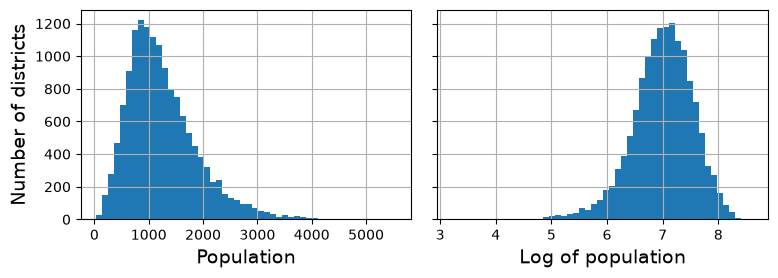

In [81]:
# extra code – this cell generates Figure 2–17
fig, axs = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
housing["population"].hist(ax=axs[0], bins=50)
housing["population"].apply(np.log).hist(ax=axs[1], bins=50)
axs[0].set_xlabel("Population")
axs[1].set_xlabel("Log of population")
axs[0].set_ylabel("Number of districts")
save_fig("long_tail_plot")
plt.show()

¿Y si reemplazamos cada valor por su percentil?

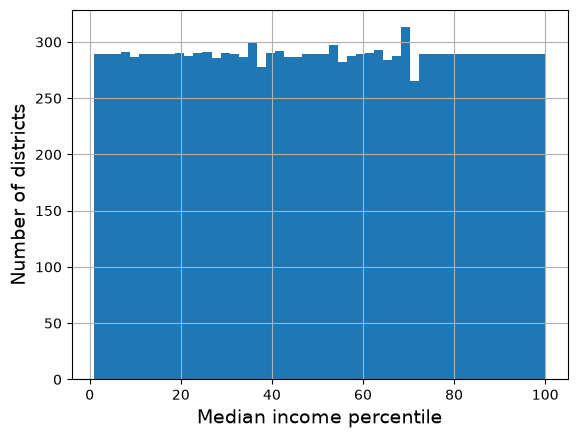

In [82]:
# extra code – just shows that we get a uniform distribution
percentiles = [np.percentile(housing["median_income"], p)
               for p in range(1, 100)]
flattened_median_income = pd.cut(housing["median_income"],
                                 bins=[-np.inf] + percentiles + [np.inf],
                                 labels=range(1, 100 + 1))
flattened_median_income.hist(bins=50)
plt.xlabel("Median income percentile")
plt.ylabel("Number of districts")
plt.show()
# Note: incomes below the 1st percentile are labeled 1, and incomes above the
# 99th percentile are labeled 100. This is why the distribution below ranges
# from 1 to 100 (not 0 to 100).

In [83]:
from sklearn.metrics.pairwise import rbf_kernel

age_simil_35 = rbf_kernel(housing[["housing_median_age"]], [[35]], gamma=0.1)

**📘 Explicación adicional — Similitud por función RBF (Radial Basis Function)**

`rbf_kernel` mide **cuán parecido** es cada valor respecto de un punto de referencia (acá, 35 años de antigüedad). La función gaussiana RBF es:

$$\phi(x) = \exp\!\big(-\gamma \, \lVert x - \ell \rVert^{2}\big)$$

donde $\ell$ es el punto de referencia (el *landmark*) y $\gamma$ controla cuán rápido decae la similitud con la distancia.

- Si $x = \ell$ → distancia 0 → $\phi = 1$ (máxima similitud).
- A medida que $x$ se aleja de $\ell$, $\phi$ cae suavemente hacia 0.
- **$\gamma$ grande** → campana angosta: solo valores muy cercanos son "similares".
- **$\gamma$ chico** → campana ancha: la similitud decae lento.

**¿Para qué sirve acá?** Permite crear features no lineales que capturan la idea de "cercanía a un valor característico". En el notebook se usa la misma idea para medir la similitud de cada distrito respecto de los centros de clusters geográficos (`ClusterSimilarity`), transformando latitud/longitud en features más informativas que las coordenadas crudas.

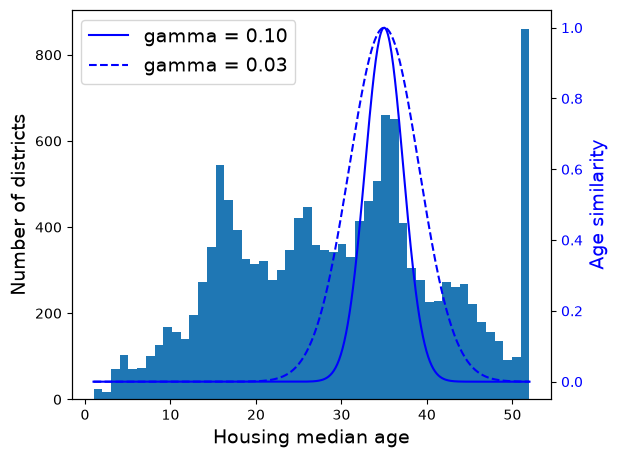

In [84]:
# extra code – this cell generates Figure 2–18

ages = np.linspace(housing["housing_median_age"].min(),
                   housing["housing_median_age"].max(),
                   500).reshape(-1, 1)
gamma1 = 0.1
gamma2 = 0.03
rbf1 = rbf_kernel(ages, [[35]], gamma=gamma1)
rbf2 = rbf_kernel(ages, [[35]], gamma=gamma2)

fig, ax1 = plt.subplots()

ax1.set_xlabel("Housing median age")
ax1.set_ylabel("Number of districts")
ax1.hist(housing["housing_median_age"], bins=50)

ax2 = ax1.twinx()  # create a twin axis that shares the same x-axis
color = "blue"
ax2.plot(ages, rbf1, color=color, label="gamma = 0.10")
ax2.plot(ages, rbf2, color=color, label="gamma = 0.03", linestyle="--")
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylabel("Age similarity", color=color)

plt.legend(loc="upper left")
save_fig("age_similarity_plot")
plt.show()

### inverse_transform() en Scikit-learn

`inverse_transform()` permite revertir una transformación y recuperar los datos en su escala original.

- `fit()`: aprende los parámetros de la transformación.
- `transform()`: transforma los datos.
- `fit_transform()`: aprende y transforma los datos.
- `inverse_transform()`: revierte la transformación.

**Ejemplo con logaritmos:**

- `np.log1p(x)`: transforma los datos calculando ln(1+x).
- `np.expm1(x)`: revierte la transformación calculando e^x-1.

**¿Para qué sirve?**

Permite recuperar valores interpretables después de aplicar transformaciones, especialmente cuando transformamos la variable objetivo antes de entrenar un modelo.

**Importante:** no todas las transformaciones tienen inversa. Solo podemos utilizar `inverse_transform()` cuando el transformador la implementa.

In [85]:
from sklearn.linear_model import LinearRegression

target_scaler = StandardScaler()
scaled_labels = target_scaler.fit_transform(housing_labels.to_frame())
print(scaled_labels)

model = LinearRegression()
model.fit(housing[["median_income"]], scaled_labels)
some_new_data = housing[["median_income"]].iloc[:5]  # pretend this is new data

scaled_predictions = model.predict(some_new_data)
predictions = target_scaler.inverse_transform(scaled_predictions)
predictions

[[ 2.51182605]
 [-0.91615817]
 [-0.96639819]
 ...
 [-0.49360371]
 [ 2.65717222]
 [ 0.2644823 ]]


array([[307649.58358784],
       [143451.50154782],
       [135759.63057829],
       [192702.83891231],
       [184498.77560018]])

In [86]:
predictions

array([[307649.58358784],
       [143451.50154782],
       [135759.63057829],
       [192702.83891231],
       [184498.77560018]])

In [87]:
from sklearn.compose import TransformedTargetRegressor

model = TransformedTargetRegressor(LinearRegression(),
                                   transformer=StandardScaler())
model.fit(housing[["median_income"]], housing_labels)
predictions = model.predict(some_new_data)

**📘 Explicación adicional — Escalar la variable objetivo y `TransformedTargetRegressor`**

En estas celdas se escala también el **objetivo** (`median_house_value`), no solo las features. Modelos como la regresión lineal pueden funcionar mejor cuando el target está en una escala razonable o menos sesgado.

- La forma manual: `target_scaler.fit_transform(...)` para escalar, entrenar, predecir, y luego `target_scaler.inverse_transform(...)` para **volver a dólares** la predicción. El riesgo es olvidarse del `inverse_transform` y reportar predicciones en la escala equivocada.
- La forma recomendada: `TransformedTargetRegressor(regressor, transformer=...)` encapsula ese ida-y-vuelta. Internamente transforma `y` antes de entrenar y **des-transforma automáticamente** las predicciones, de modo que `predict()` ya devuelve valores en la escala original.

**Por qué conviene:** menos código manual, menos errores, y se integra limpio dentro de un `Pipeline`.

In [88]:
predictions

array([307649.58358784, 143451.50154782, 135759.63057829, 192702.83891231,
       184498.77560018])

## Transformadores personalizados (Custom Transformers)

Para crear transformadores simples:

In [89]:
from sklearn.preprocessing import FunctionTransformer

log_transformer = FunctionTransformer(np.log, inverse_func=np.exp)
log_pop = log_transformer.transform(housing[["population"]])
print(log_pop)
print(housing[['population']])

       population
14973    6.501290
3785     6.331502
14689    7.520235
20507    7.555905
1286     6.542472
...           ...
14207    6.843750
13105    7.257708
19301    7.942362
19121    7.452982
19888    6.525030

[14448 rows x 1 columns]
       population
14973       666.0
3785        562.0
14689      1845.0
20507      1912.0
1286        694.0
...           ...
14207       938.0
13105      1419.0
19301      2814.0
19121      1725.0
19888       682.0

[14448 rows x 1 columns]


In [90]:
rbf_transformer = FunctionTransformer(rbf_kernel,
                                      kw_args=dict(Y=[[35.]], gamma=0.1))
age_simil_35 = rbf_transformer.transform(housing[["housing_median_age"]])

In [91]:
age_simil_35

array([[8.20849986e-02],
       [6.70320046e-01],
       [8.48904403e-15],
       ...,
       [9.55316054e-22],
       [6.70320046e-01],
       [3.03539138e-04]], shape=(14448, 1))

In [92]:
sf_coords = 37.7749, -122.41
sf_transformer = FunctionTransformer(rbf_kernel,
                                     kw_args=dict(Y=[sf_coords], gamma=0.1))
sf_simil = sf_transformer.transform(housing[["latitude", "longitude"]])

In [93]:
sf_simil

array([[0.05258419],
       [0.94864161],
       [0.01192662],
       ...,
       [0.00388525],
       [0.05038518],
       [0.99868067]], shape=(14448, 1))

In [94]:
ratio_transformer = FunctionTransformer(lambda X: X[:, [0]] / X[:, [1]])
ratio_transformer.transform(np.array([[1., 2.], [3., 4.]]))

array([[0.5 ],
       [0.75]])

In [95]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_array, check_is_fitted

class StandardScalerClone(BaseEstimator, TransformerMixin):
    def __init__(self, with_mean=True):  # no *args or **kwargs!
        self.with_mean = with_mean

    def fit(self, X, y=None):  # y is required even though we don't use it
        X = check_array(X)  # checks that X is an array with finite float values
        self.mean_ = X.mean(axis=0)
        self.scale_ = X.std(axis=0)
        self.scale_[self.scale_ == 0] = 1  # Avoid division by zero for constant features
        self.n_features_in_ = X.shape[1]  # every estimator stores this in fit()
        return self  # always return self!

    def transform(self, X):
        check_is_fitted(self)  # looks for learned attributes (with trailing _)
        X = check_array(X)
        assert self.n_features_in_ == X.shape[1]
        if self.with_mean:
            X = X - self.mean_
        return X / self.scale_

In [96]:
from sklearn.cluster import KMeans

class ClusterSimilarity(BaseEstimator, TransformerMixin):
    def __init__(self, n_clusters=10, gamma=1.0, random_state=None):
        self.n_clusters = n_clusters
        self.gamma = gamma
        self.random_state = random_state

    def fit(self, X, y=None, sample_weight=None):
        self.kmeans_ = KMeans(self.n_clusters, n_init=10,
                              random_state=self.random_state)
        self.kmeans_.fit(X, sample_weight=sample_weight)
        return self  # always return self!

    def transform(self, X):
        return rbf_kernel(X, self.kmeans_.cluster_centers_, gamma=self.gamma)
    
    def get_feature_names_out(self, names=None):
        return [f"Cluster {i} similarity" for i in range(self.n_clusters)]

**Advertencia**:
* Hubo un cambio en Scikit-Learn 1.3.0 que afectó al generador de números aleatorios para la inicialización de `KMeans`. Por lo tanto, los resultados serán distintos a los del libro si usás Scikit-Learn ≥ 1.3. Eso no es un problema, siempre que no esperes que las salidas sean perfectamente idénticas.
* A lo largo de este notebook, cuando no se estableció `n_init` al crear un estimador `KMeans`, lo fijé explícitamente en `n_init=10` para evitar una advertencia sobre el hecho de que el valor por defecto de este hiperparámetro cambiará de 10 a `"auto"` en Scikit-Learn 1.4.
* El libro no dejaba claro que establecer `sample_weight=housing_labels` era solo a modo de ejemplo; en realidad no se usa durante el entrenamiento. Así que elimino el argumento `sample_weight` más abajo, y la figura siguiente corresponde a los clusters realmente usados durante el entrenamiento (a diferencia de la Figura 2-19 del libro). ¡Disculpas si esto generó alguna confusión!

In [97]:
cluster_simil = ClusterSimilarity(n_clusters=10, gamma=1., random_state=42)
similarities = cluster_simil.fit_transform(housing[["latitude", "longitude"]])

In [98]:
similarities[:3].round(2)

array([[0.95, 0.  , 0.05, 0.03, 0.  , 0.07, 0.  , 0.  , 0.4 , 0.  ],
       [0.  , 0.73, 0.  , 0.  , 0.49, 0.  , 0.28, 0.16, 0.  , 0.  ],
       [0.28, 0.  , 0.  , 0.46, 0.  , 0.  , 0.  , 0.  , 0.86, 0.  ]])

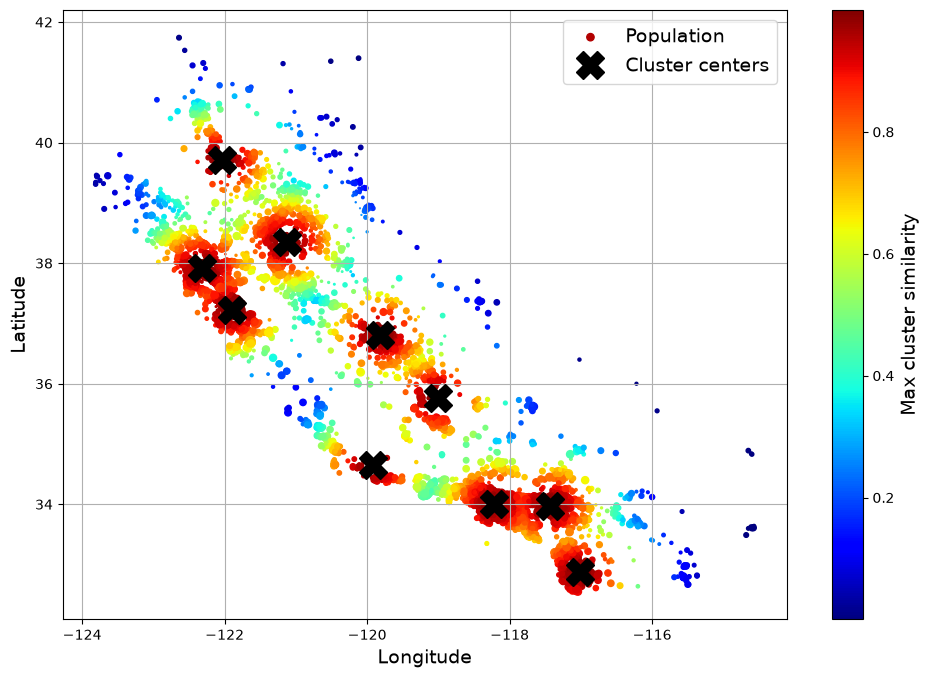

In [99]:
# extra code – this cell generates Figure 2–19

housing_renamed = housing.rename(columns={
    "latitude": "Latitude", "longitude": "Longitude",
    "population": "Population",
    "median_house_value": "Median house value (ᴜsᴅ)"})
housing_renamed["Max cluster similarity"] = similarities.max(axis=1)

housing_renamed.plot(kind="scatter", x="Longitude", y="Latitude", grid=True,
                     s=housing_renamed["Population"] / 100, label="Population",
                     c="Max cluster similarity",
                     cmap="jet", colorbar=True,
                     legend=True, sharex=False, figsize=(10, 7))
plt.plot(cluster_simil.kmeans_.cluster_centers_[:, 1],
         cluster_simil.kmeans_.cluster_centers_[:, 0],
         linestyle="", color="black", marker="X", markersize=20,
         label="Cluster centers")
plt.legend(loc="upper right")
save_fig("district_cluster_plot")
plt.show()

## Pipelines de transformación

Ahora construyamos un pipeline para preprocesar los atributos numéricos:

In [100]:
from sklearn.pipeline import Pipeline

num_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("standardize", StandardScaler()),
])

**📘 Explicación adicional — ¿Qué es un `Pipeline` y por qué usarlo?**

1. **¿Qué hacemos?** Encadenamos varios transformadores (y opcionalmente un estimador final) en un único objeto. Acá: imputar la mediana → escalar.

2. **¿Por qué?** Para que **toda la secuencia de preparación se ajuste con el train y se aplique idéntica** a validación, test y producción. Hacerlo a mano invita a olvidarse un paso o, peor, a ajustar un transformador con datos de test (*data leakage*).

3. **¿Cómo funciona?** Al llamar `pipeline.fit(X)`, se ejecuta `fit_transform` en cada paso en orden; al llamar `transform`/`predict`, solo `transform`. Todos los pasos intermedios deben ser transformadores; solo el último puede ser un estimador final.

4. **Parámetros/convenciones útiles:** `make_pipeline` nombra los pasos automáticamente; se accede con `pipeline.named_steps[...]` o indexado `pipeline[:-1]`; los hiperparámetros se referencian con doble guion bajo (`simpleimputer__strategy`), lo que permite ajustarlos con Grid/Randomized Search.

5. **Resultado esperado:** un objeto reutilizable que preprocesa de forma consistente y reproducible.

6. **¿Cuándo se usa?** Siempre que haya más de un paso de preprocesamiento: es la **columna vertebral de cualquier proyecto serio de ML tabular**.

In [101]:
from sklearn.pipeline import make_pipeline

num_pipeline = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())

In [102]:
from sklearn import set_config

set_config(display='diagram')

num_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('simpleimputer', ...), ('standardscaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimato

In [103]:
housing_num_prepared = num_pipeline.fit_transform(housing_num)
housing_num_prepared[:2].round(2)

array([[-1.42,  1.01,  1.86,  0.31,  1.37,  0.14,  1.39, -0.94],
       [ 0.6 , -0.7 ,  0.91, -0.31, -0.44, -0.69, -0.37,  1.17]])

In [104]:
def monkey_patch_get_signature_names_out():
    """Monkey patch some classes which did not handle get_feature_names_out()
       correctly in Scikit-Learn 1.0.*."""
    from inspect import Signature, signature, Parameter
    import pandas as pd
    from sklearn.impute import SimpleImputer
    from sklearn.pipeline import make_pipeline, Pipeline
    from sklearn.preprocessing import FunctionTransformer, StandardScaler

    default_get_feature_names_out = StandardScaler.get_feature_names_out

    if not hasattr(SimpleImputer, "get_feature_names_out"):
      print("Monkey-patching SimpleImputer.get_feature_names_out()")
      SimpleImputer.get_feature_names_out = default_get_feature_names_out

    if not hasattr(FunctionTransformer, "get_feature_names_out"):
        print("Monkey-patching FunctionTransformer.get_feature_names_out()")
        orig_init = FunctionTransformer.__init__
        orig_sig = signature(orig_init)

        def __init__(*args, feature_names_out=None, **kwargs):
            orig_sig.bind(*args, **kwargs)
            orig_init(*args, **kwargs)
            args[0].feature_names_out = feature_names_out

        __init__.__signature__ = Signature(
            list(signature(orig_init).parameters.values()) + [
                Parameter("feature_names_out", Parameter.KEYWORD_ONLY)])

        def get_feature_names_out(self, names=None):
            if callable(self.feature_names_out):
                return self.feature_names_out(self, names)
            assert self.feature_names_out == "one-to-one"
            return default_get_feature_names_out(self, names)

        FunctionTransformer.__init__ = __init__
        FunctionTransformer.get_feature_names_out = get_feature_names_out

monkey_patch_get_signature_names_out()

In [105]:
df_housing_num_prepared = pd.DataFrame(
    housing_num_prepared, columns=num_pipeline.get_feature_names_out(),
    index=housing_num.index)

In [106]:
df_housing_num_prepared.head(2)  # extra code

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
13096,-1.423037,1.013606,1.861119,0.311912,1.368167,0.137460,1.394812,-0.936491
14973,0.596394,-0.702103,0.907630,-0.308620,-0.435925,-0.693771,-0.373485,1.171942


In [107]:
num_pipeline.steps

[('simpleimputer', SimpleImputer(strategy='median')),
 ('standardscaler', StandardScaler())]

In [108]:
num_pipeline[1]

StandardScaler()

In [109]:
num_pipeline[:-1]

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('simpleimputer', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['longitude','latitude','housing_median_age',...,'population','households', 'median_income']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data ty

In [110]:
num_pipeline.named_steps["simpleimputer"]

,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['longitude','latitude','housing_median_age',...,'population','households', 'median_income']"
indicator_ indicator_: :class:`~sklearn.impute.MissingIndicator`Indicator used to add binary indicators for missing values.`None` if `add_indicator=False`.,NoneType,None
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
"statistics_ statistics_: array of shape (n_features,)The imputation fill value for each feature.Computing statistics can result in `np.nan` values.During :meth:`transform`, features corresponding to `np.nan`statistics will be discarded.","ndarray[float64](8,)","[-118.51, 34.26, 29. ,...,1167. , 408. , 3.54]"


In [111]:
num_pipeline.set_params(simpleimputer__strategy="median")

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('simpleimputer', ...), ('standardscaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['longitude','latitude','housing_median_age',...,'population','households', 'median_income']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for 

In [112]:
from sklearn.compose import ColumnTransformer

num_attribs = ["longitude", "latitude", "housing_median_age", "total_rooms",
               "total_bedrooms", "population", "households", "median_income"]
cat_attribs = ["ocean_proximity"]

cat_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore"))

preprocessing = ColumnTransformer([
    ("num", num_pipeline, num_attribs),
    ("cat", cat_pipeline, cat_attribs),
])

In [113]:
from sklearn.compose import make_column_selector, make_column_transformer

preprocessing = make_column_transformer(
    (num_pipeline, make_column_selector(dtype_include=np.number)),
    (cat_pipeline, make_column_selector(dtype_include=object)),
)

In [114]:
housing_prepared = preprocessing.fit_transform(housing)

In [115]:
# extra code – shows that we can get a DataFrame out if we want
housing_prepared_fr = pd.DataFrame(
    housing_prepared,
    columns=preprocessing.get_feature_names_out(),
    index=housing.index)
housing_prepared_fr.head(2)

,pipeline-1__longitude,pipeline-1__latitude,pipeline-1__housing_median_age,pipeline-1__total_rooms,pipeline-1__total_bedrooms,pipeline-1__population,pipeline-1__households,pipeline-1__median_income,pipeline-2__ocean_proximity_<1H OCEAN,pipeline-2__ocean_proximity_INLAND,pipeline-2__ocean_proximity_ISLAND,pipeline-2__ocean_proximity_NEAR BAY,pipeline-2__ocean_proximity_NEAR OCEAN
14973,0.595527,-0.692801,0.875904,-0.257539,-0.479342,-0.911423,-0.367756,1.383990,1.0,0.0,0.0,0.0,0.0
3785,-1.273032,1.361924,0.292345,-1.043780,-1.077558,-1.073350,-1.092179,-0.804668,0.0,1.0,0.0,0.0,0.0


In [116]:
def column_ratio(X):
    return X[:, [0]] / X[:, [1]]

def ratio_name(function_transformer, feature_names_in):
    return ["ratio"]  # feature names out

def ratio_pipeline():
    return make_pipeline(
        SimpleImputer(strategy="median"),
        FunctionTransformer(column_ratio, feature_names_out=ratio_name),
        StandardScaler())

log_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    FunctionTransformer(np.log, feature_names_out="one-to-one"),
    StandardScaler())
cluster_simil = ClusterSimilarity(n_clusters=10, gamma=1., random_state=42)
default_num_pipeline = make_pipeline(SimpleImputer(strategy="median"),
                                     StandardScaler())
preprocessing = ColumnTransformer([
        ("bedrooms", ratio_pipeline(), ["total_bedrooms", "total_rooms"]),
        ("rooms_per_house", ratio_pipeline(), ["total_rooms", "households"]),
        ("people_per_house", ratio_pipeline(), ["population", "households"]),
        ("log", log_pipeline, ["total_bedrooms", "total_rooms", "population",
                               "households", "median_income"]),
        ("geo", cluster_simil, ["latitude", "longitude"]),
        ("cat", cat_pipeline, make_column_selector(dtype_include=object)),
    ],
    remainder=default_num_pipeline)  # one column remaining: housing_median_age

In [117]:
housing_prepared = preprocessing.fit_transform(housing)
housing_prepared.shape

(14448, 24)

In [118]:
preprocessing.get_feature_names_out()

array(['bedrooms__ratio', 'rooms_per_house__ratio',
       'people_per_house__ratio', 'log__total_bedrooms',
       'log__total_rooms', 'log__population', 'log__households',
       'log__median_income', 'geo__Cluster 0 similarity',
       'geo__Cluster 1 similarity', 'geo__Cluster 2 similarity',
       'geo__Cluster 3 similarity', 'geo__Cluster 4 similarity',
       'geo__Cluster 5 similarity', 'geo__Cluster 6 similarity',
       'geo__Cluster 7 similarity', 'geo__Cluster 8 similarity',
       'geo__Cluster 9 similarity', 'cat__ocean_proximity_<1H OCEAN',
       'cat__ocean_proximity_INLAND', 'cat__ocean_proximity_ISLAND',
       'cat__ocean_proximity_NEAR BAY', 'cat__ocean_proximity_NEAR OCEAN',
       'remainder__housing_median_age'], dtype=object)

**🔎 Comparación de técnicas — Transformaciones manuales vs. `Pipeline` + `ColumnTransformer`**

| | Transformaciones manuales | `Pipeline` + `ColumnTransformer` |
|---|---|---|
| **Qué hace** | Se aplica cada `fit`/`transform` a mano, paso por paso. | Un solo objeto orquesta distintos pipelines para distintos grupos de columnas (numéricas vs. categóricas). |
| **Riesgo de leakage** | Alto: es fácil ajustar algo con el test o saltearse un paso. | Bajo: todo se ajusta con el train y se reaplica solo con `transform`. |
| **Reproducibilidad** | Baja; depende del orden en que se ejecuten las celdas. | Alta; el flujo queda encapsulado. |
| **Producción** | Difícil de serializar y mantener. | Se guarda entero con `joblib` y se reutiliza igual en producción. |

**¿Por qué el notebook usa `ColumnTransformer`?** Porque las columnas numéricas y la categórica (`ocean_proximity`) necesitan tratamientos distintos. `ColumnTransformer` aplica el pipeline numérico a unas columnas y el `OneHotEncoder` a la otra, y `get_feature_names_out()` recupera los nombres resultantes.

**💼 ¿Qué utilizaría en un proyecto real?**

1. **Elección recomendada:** **siempre** `Pipeline` + `ColumnTransformer`. No es solo "más prolijo": es la forma de garantizar que entrenamiento y producción hagan exactamente lo mismo.
2. **Uso en la industria:** es el estándar de facto en Scikit-Learn. Para flujos más grandes se combina con herramientas de orquestación (Airflow, Kubeflow) o *feature stores*, pero la unidad de preprocesamiento sigue siendo el pipeline.
3. **Criterios de decisión:** casi no hay trade-off; el único "costo" es aprender la sintaxis.
4. **Ejemplo laboral:** un modelo de riesgo que recibe JSON de una API: el mismo pipeline serializado imputa, escala y codifica el request entrante tal como en entrenamiento.
5. **Buenas prácticas:** meter **todo** el preprocesamiento dentro del pipeline (nada de transformaciones sueltas antes del split), versionar el pipeline junto al modelo, y validar con el pipeline completo para que el CV no tenga leakage.
6. **Qué debería recordar:** el pipeline no es opcional en producción; manipular los datos a mano queda solo para exploración rápida.

# Seleccionar y entrenar un modelo

## Entrenar y evaluar sobre el conjunto de entrenamiento

In [119]:
from sklearn.linear_model import LinearRegression

lin_reg = make_pipeline(preprocessing, LinearRegression())
lin_reg.fit(housing, housing_labels)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['longitude','latitude','housing_median_age',...,'households', 'median_income','ocean_proximity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('bedrooms', ...), ('rooms_per_house', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit

Probemos el pipeline de preprocesamiento completo sobre unas pocas instancias de entrenamiento:

In [120]:
housing_predictions = lin_reg.predict(housing)
housing_predictions[:5].round(-2)  # -2 = rounded to the nearest hundred

array([379800., 122500.,  99600., 341400., 200300.])

Comparamos contra los valores reales:

In [121]:
housing_labels.iloc[:5].values

array([483800., 101700.,  96100., 361800.,  92600.])

In [122]:
# extra code – computes the error ratios discussed in the book
error_ratios = housing_predictions[:5].round(-2) / housing_labels.iloc[:5].values - 1
print(", ".join([f"{100 * ratio:.1f}%" for ratio in error_ratios]))

-21.5%, 20.5%, 3.6%, -5.6%, 116.3%


**Advertencia**: En versiones recientes de Scikit-Learn, debés usar `root_mean_squared_error(labels, predictions)` para calcular el RMSE, en lugar de `mean_squared_error(labels, predictions, squared=False)`. El siguiente bloque `try`/`except` intenta importar `root_mean_squared_error` y, si falla, simplemente lo define.

In [123]:
try:
    from sklearn.metrics import root_mean_squared_error
except ImportError:
    from sklearn.metrics import mean_squared_error

    def root_mean_squared_error(labels, predictions):
        return mean_squared_error(labels, predictions, squared=False)

lin_rmse = root_mean_squared_error(housing_labels, housing_predictions)
lin_rmse

65778.48225643061

In [124]:
from sklearn.tree import DecisionTreeRegressor

tree_reg = make_pipeline(preprocessing, DecisionTreeRegressor(random_state=42))
tree_reg.fit(housing, housing_labels)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('decisiontreeregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['longitude','latitude','housing_median_age',...,'households', 'median_income','ocean_proximity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('bedrooms', ...), ('rooms_per_house', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto

In [125]:
housing_predictions = tree_reg.predict(housing)
tree_rmse = root_mean_squared_error(housing_labels, housing_predictions)
tree_rmse
print(housing_predictions)


[483800. 101700.  96100. ... 148800. 500001. 233300.]


**📘 Explicación adicional — Métricas de error: MAE, MSE y RMSE**

Para un problema de regresión con $m$ ejemplos, predicción $\hat{y}_i$ y valor real $y_i$:

$$\text{MAE} = \frac{1}{m}\sum_{i=1}^{m}\lvert \hat{y}_i - y_i\rvert \qquad \text{MSE} = \frac{1}{m}\sum_{i=1}^{m}(\hat{y}_i - y_i)^2 \qquad \text{RMSE} = \sqrt{\text{MSE}}$$

| Métrica | Unidades | Penaliza errores grandes | Robustez a outliers |
|---|---|---|---|
| **MAE** | las del objetivo | lineal | más robusta |
| **MSE** | al cuadrado | cuadrática (fuerte) | sensible |
| **RMSE** | las del objetivo | cuadrática (fuerte) | sensible |

- **RMSE** es la métrica por defecto del capítulo: está en las mismas unidades que el objetivo (dólares) y penaliza más los errores grandes, algo deseable cuando un error grande es especialmente costoso.
- **MAE** conviene cuando hay muchos outliers y no querés que dominen la métrica.

**Intuición:** RMSE ≈ "desviación estándar de los errores". Un RMSE de \$50.000 significa que, típicamente, las predicciones se desvían unos \$50.000 del valor real.

## Mejor evaluación usando validación cruzada (Cross-Validation)

**📘 Explicación adicional — Validación cruzada (k-fold Cross-Validation)**

1. **¿Qué hacemos?** `cross_val_score` divide el train en $k$ pliegues (folds). Entrena con $k-1$ y evalúa con el restante, rotando $k$ veces. Obtenemos $k$ puntajes.

2. **¿Por qué?** Una única división train/validación da una estimación con mucha varianza (depende de qué filas cayeron en validación). El CV promedia varias divisiones → estimación **más estable** del error de generalización, y además una desviación estándar que indica cuán confiable es.

3. **¿Cómo funciona?** Con `cv=10`, cada fold usa ~90% para entrenar y ~10% para validar. Scikit-Learn maximiza un *score* (por eso se usa `neg_root_mean_squared_error` y luego se niega: `-scores`).

4. **Parámetros importantes:** `cv` (número de folds; típico 5 o 10), `scoring` (la métrica), y que el estimador debe ser el **pipeline completo** para que el preprocesamiento se ajuste dentro de cada fold (y no haya leakage).

5. **Resultado esperado:** una media y una dispersión del RMSE de validación.

6. **¿Cuándo se usa?** Para comparar modelos y ajustar hiperparámetros **sin tocar el test set**. Es la base de `GridSearchCV` y `RandomizedSearchCV`.

In [126]:
from sklearn.model_selection import cross_val_score

tree_rmses = -cross_val_score(tree_reg, housing, housing_labels,
                              scoring="neg_root_mean_squared_error", cv=10)

In [127]:
pd.Series(tree_rmses).describe()

count       10.000000
mean     65575.962152
std       2559.867825
min      62691.129610
25%      63815.447134
50%      64538.499844
75%      66985.142209
max      70267.780062
dtype: float64

In [128]:
# extra code – computes the error stats for the linear model
lin_rmses = -cross_val_score(lin_reg, housing, housing_labels,
                              scoring="neg_root_mean_squared_error", cv=10)
pd.Series(lin_rmses).describe()

count       10.000000
mean     67856.971843
std       4282.797978
min      63653.224894
25%      65648.552875
50%      67242.573995
75%      68167.274730
max      79024.043455
dtype: float64

In [129]:
housing

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
14973,-118.38,34.14,40.0,1965.0,354.0,666.0,357.0,6.0876,<1H OCEAN
3785,-121.98,38.36,33.0,1083.0,217.0,562.0,203.0,2.4330,INLAND
14689,-117.11,33.75,17.0,4174.0,851.0,1845.0,780.0,2.2618,INLAND
20507,-118.15,33.77,36.0,4366.0,1211.0,1912.0,1172.0,3.5292,NEAR OCEAN
1286,-121.31,37.96,52.0,1829.0,301.0,694.0,319.0,3.3466,INLAND
...,...,...,...,...,...,...,...,...,...
14207,-118.40,33.86,41.0,2237.0,597.0,938.0,523.0,4.7105,<1H OCEAN
13105,-119.31,36.32,23.0,2945.0,592.0,1419.0,532.0,2.5733,INLAND
19301,-117.06,32.59,13.0,3920.0,775.0,2814.0,760.0,4.0616,NEAR OCEAN
19121,-118.40,34.06,37.0,3781.0,873.0,1725.0,838.0,4.1455,<1H OCEAN


**Advertencia:** la siguiente celda puede tardar unos minutos en ejecutarse:

In [ ]:
from sklearn.ensemble import RandomForestRegressor

forest_reg = make_pipeline(preprocessing,
                           RandomForestRegressor(random_state=42))
forest_rmses = -cross_val_score(forest_reg, housing, housing_labels,
                                scoring="neg_root_mean_squared_error", cv=10)

In [ ]:
pd.Series(forest_rmses).describe()

count       10.000000
mean     45712.814157
std       1526.379944
min      43581.732899
25%      44586.595164
50%      45444.484552
75%      47069.509995
max      47938.112716
dtype: float64

In [ ]:
housing_labels.mean()

np.float64(203819.50048449612)

Comparemos este RMSE medido con validación cruzada (el "error de validación") con el RMSE medido sobre el conjunto de entrenamiento (el "error de entrenamiento"):

In [ ]:
forest_reg.fit(housing, housing_labels)
housing_predictions = forest_reg.predict(housing)
forest_rmse = root_mean_squared_error(housing_labels, housing_predictions)
forest_rmse

16952.579457730448

**🔎 Comparación de técnicas — Los modelos evaluados: Regresión Lineal, Árbol de Decisión y Random Forest**

| | `LinearRegression` | `DecisionTreeRegressor` | `RandomForestRegressor` |
|---|---|---|---|
| **Idea** | Ajusta una combinación lineal de las features. | Parte el espacio en reglas if/else. | Promedia muchos árboles entrenados sobre submuestras (bagging). |
| **Capacidad** | Baja (solo relaciones lineales). | Alta, pero propenso a overfitting. | Alta y mucho más estable que un árbol solo. |
| **Resultado en el notebook** | Subajuste: RMSE alto. | Overfitting severo: RMSE ≈ 0 en train, alto en CV. | Mejor equilibrio: menor RMSE de validación. |
| **Interpretabilidad** | Alta (coeficientes). | Media (reglas / árbol). | Baja, pero da `feature_importances_`. |
| **Escalado necesario** | Sí (sensible a magnitudes). | No. | No. |

**¿Por qué Random Forest gana acá?** Combina muchos árboles decorrelacionados, lo que reduce la varianza del árbol individual sin aumentar demasiado el sesgo. Captura relaciones no lineales e interacciones que la regresión lineal no puede, y generaliza mucho mejor que un único árbol.

**💼 ¿Qué utilizaría en un proyecto real?**

1. **Elección recomendada:** para datos **tabulares**, un modelo de *gradient boosting* (XGBoost, LightGBM, CatBoost) o un `RandomForestRegressor` como *baseline* fuerte. La regresión lineal regularizada (Ridge/Lasso) sigue siendo excelente cuando se necesita interpretabilidad o el fenómeno es aproximadamente lineal.
2. **Uso en la industria:** boosting y random forests son los caballos de batalla en datos tabulares; los modelos lineales se usan mucho en finanzas y salud por su transparencia; las redes neuronales dominan en imágenes, texto y audio, no tanto en tablas.
3. **Criterios de decisión:** tamaño del dataset, necesidad de interpretabilidad, costo de entrenamiento/inferencia, y requisitos regulatorios.
4. **Ejemplo laboral:** para precios inmobiliarios, un LightGBM suele dar el mejor error; pero si el banco exige explicar cada predicción, podría preferirse un modelo lineal o árboles con SHAP.
5. **Buenas prácticas:** empezar con un *baseline* simple (lineal), comparar contra ensembles con validación cruzada, y recién ahí ajustar hiperparámetros del ganador. Todo dentro del mismo pipeline.
6. **Qué debería recordar:** en tablas, mi primera apuesta seria es boosting o random forest; el modelo lineal es el baseline y la opción cuando manda la interpretabilidad.

El error de entrenamiento es mucho más bajo que el error de validación, lo que generalmente significa que el modelo ha sobreajustado (overfit) el conjunto de entrenamiento. Otra posible explicación podría ser que exista una discrepancia (mismatch) entre los datos de entrenamiento y los de validación, pero no es el caso aquí, ya que ambos provienen del mismo dataset que mezclamos (shuffle) y dividimos en dos partes.

**📘 Explicación adicional — Sobreajuste (overfitting) vs. subajuste (underfitting)**

| | Subajuste (underfitting) | Sobreajuste (overfitting) |
|---|---|---|
| **Síntoma** | Error **alto** en train *y* en validación. | Error **bajo** en train pero **alto** en validación. |
| **Causa** | Modelo demasiado simple para los patrones. | Modelo demasiado complejo: memoriza ruido del train. |
| **Ejemplo en el notebook** | `LinearRegression` (error alto en ambos). | `DecisionTreeRegressor` (RMSE ≈ 0 en train, alto en CV). |
| **Cómo mitigar** | Modelo más potente, más features, menos regularización. | Más datos, regularización, menos complejidad, *ensembles*. |

**La señal diagnóstica clave** es justamente la que se observa en estas celdas: cuando el **error de entrenamiento es mucho menor que el de validación**, el modelo está sobreajustando. Comparar ambos errores es la forma estándar de detectarlo.

**⚠️ Error común — Confundir un buen desempeño en entrenamiento con capacidad de generalización**

El `DecisionTreeRegressor` da RMSE ≈ 0 **sobre el train**. Si uno se quedara con ese número, creería tener un modelo perfecto. Pero la validación cruzada revela un error alto: el árbol memorizó los datos, no aprendió a generalizar.

Moraleja: **nunca juzgues un modelo por su error de entrenamiento.** Lo que importa es el error sobre datos no vistos (validación / test). Un error de entrenamiento sospechosamente bajo es una bandera roja de overfitting, no un logro.

# Ajuste fino de tu modelo (Fine-Tune)

## Búsqueda en grilla (Grid Search)

**Advertencia:** la siguiente celda puede tardar unos minutos en ejecutarse:

In [ ]:
from sklearn.model_selection import GridSearchCV

full_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("random_forest", RandomForestRegressor(random_state=42)),
])
param_grid = [
    {'preprocessing__geo__n_clusters': [5, 8, 10],
     'random_forest__max_features': [4, 6, 8]},
    {'preprocessing__geo__n_clusters': [10, 15],
     'random_forest__max_features': [6, 8, 10]},
]
grid_search = GridSearchCV(full_pipeline, param_grid, cv=3,
                           scoring='neg_root_mean_squared_error')
grid_search.fit(housing, housing_labels)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'preprocessing__geo__n_clusters': [5, 8, ...], 'random_forest__max_features': [4, 6, ...]}, {'preprocessing__geo__n_clusters': [10, 15], 'random_forest__max_features': [6, 8, ...]}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cr

Podés obtener la lista completa de hiperparámetros disponibles para el ajuste observando `full_pipeline.get_params().keys()`:

In [ ]:
# extra code – shows part of the output of get_params().keys()
print(str(full_pipeline.get_params().keys())[:1000] + "...")

dict_keys(['memory', 'steps', 'transform_input', 'verbose', 'preprocessing', 'random_forest', 'preprocessing__n_jobs', 'preprocessing__remainder__memory', 'preprocessing__remainder__steps', 'preprocessing__remainder__transform_input', 'preprocessing__remainder__verbose', 'preprocessing__remainder__simpleimputer', 'preprocessing__remainder__standardscaler', 'preprocessing__remainder__simpleimputer__add_indicator', 'preprocessing__remainder__simpleimputer__copy', 'preprocessing__remainder__simpleimputer__fill_value', 'preprocessing__remainder__simpleimputer__keep_empty_features', 'preprocessing__remainder__simpleimputer__missing_values', 'preprocessing__remainder__simpleimputer__strategy', 'preprocessing__remainder__standardscaler__copy', 'preprocessing__remainder__standardscaler__with_mean', 'preprocessing__remainder__standardscaler__with_std', 'preprocessing__remainder', 'preprocessing__sparse_threshold', 'preprocessing__transformer_weights', 'preprocessing__transformers', 'preprocessi

La mejor combinación de hiperparámetros encontrada:

In [ ]:
grid_search.best_params_

{'preprocessing__geo__n_clusters': 15, 'random_forest__max_features': 6}

In [ ]:
grid_search.best_estimator_

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('random_forest', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['longitude','latitude','housing_median_age',...,'households', 'median_income','ocean_proximity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('bedrooms', ...), ('rooms_per_house', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will 

Veamos el puntaje (score) de cada combinación de hiperparámetros probada durante la búsqueda en grilla:

In [ ]:
cv_res = pd.DataFrame(grid_search.cv_results_)
cv_res.sort_values(by="mean_test_score", ascending=False, inplace=True)

# extra code – these few lines of code just make the DataFrame look nicer
cv_res = cv_res[["param_preprocessing__geo__n_clusters",
                 "param_random_forest__max_features", "split0_test_score",
                 "split1_test_score", "split2_test_score", "mean_test_score"]]
score_cols = ["split0", "split1", "split2", "mean_test_rmse"]
cv_res.columns = ["n_clusters", "max_features"] + score_cols
cv_res[score_cols] = -cv_res[score_cols].round().astype(np.int64)

cv_res.head()

,n_clusters,max_features,split0,split1,split2,mean_test_rmse
12,15,6,41811,43463,42184,42486
13,15,8,42086,44078,42782,42982
14,15,10,42644,44122,42921,43229
7,10,6,43255,44499,43575,43776
9,10,6,43255,44499,43575,43776


## Búsqueda aleatoria (Randomized Search)

In [ ]:
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingRandomSearchCV

Probamos 30 (`n_iter` × `cv`) combinaciones aleatorias de hiperparámetros:

**Advertencia:** la siguiente celda puede tardar unos minutos en ejecutarse:

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_distribs = {'preprocessing__geo__n_clusters': randint(low=3, high=50),
                  'random_forest__max_features': randint(low=2, high=20)}

rnd_search = RandomizedSearchCV(
    full_pipeline, param_distributions=param_distribs, n_iter=10, cv=3,
    scoring='neg_root_mean_squared_error', random_state=42)

rnd_search.fit(housing, housing_labels)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'preprocessing__geo__n_clusters': <scipy.stats....002A0406C3CB0>, 'random_forest__max_features': <scipy.stats....002A03D877F50>}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchC

In [ ]:
# extra code – displays the random search results
cv_res = pd.DataFrame(rnd_search.cv_results_)
cv_res.sort_values(by="mean_test_score", ascending=False, inplace=True)
cv_res = cv_res[["param_preprocessing__geo__n_clusters",
                 "param_random_forest__max_features", "split0_test_score",
                 "split1_test_score", "split2_test_score", "mean_test_score"]]
cv_res.columns = ["n_clusters", "max_features"] + score_cols
cv_res[score_cols] = -cv_res[score_cols].round().astype(np.int64)
cv_res.head()

,n_clusters,max_features,split0,split1,split2,mean_test_rmse
1,45,9,39937,42053,40021,40670
8,32,7,40366,42252,40730,41116
5,42,4,40581,42688,40947,41405
0,41,16,40695,42780,41005,41493
2,23,8,41073,42910,41655,41879


**🔎 Comparación de técnicas — `GridSearchCV` vs. `RandomizedSearchCV`**

| | `GridSearchCV` | `RandomizedSearchCV` |
|---|---|---|
| **Cómo explora** | Prueba **todas** las combinaciones de una grilla discreta. | Muestrea un número fijo (`n_iter`) de combinaciones al azar desde distribuciones. |
| **Costo** | Explosión combinatoria: crece como el producto de las opciones. | Controlado: lo fijás con `n_iter`. |
| **Espacios continuos** | Hay que discretizarlos a mano. | Los maneja naturalmente (`uniform`, `loguniform`, `expon`...). |
| **Cuándo conviene** | Pocos hiperparámetros, con pocos valores candidatos cada uno. | Muchos hiperparámetros o rangos amplios/continuos. |

**Por qué suele ganar la aleatoria:** con el mismo presupuesto de evaluaciones, la búsqueda aleatoria cubre mejor cada dimensión importante, en vez de gastar evaluaciones en combinaciones redundantes de dimensiones que no importan. Por eso en el notebook se observa que `RandomizedSearchCV` encuentra mejores hiperparámetros que `GridSearchCV` en tiempos comparables.

**💼 ¿Qué utilizaría en un proyecto real?**

1. **Elección recomendada:** `RandomizedSearchCV` para una primera exploración amplia; refinar luego con una grilla acotada (`GridSearchCV`) alrededor de la mejor zona.
2. **Uso en la industria:** para búsquedas serias se usan librerías de **optimización bayesiana / early-stopping** como Optuna, Hyperopt o Ray Tune, que son más eficientes que el muestreo aleatorio puro. `HalvingRandomSearchCV` (que aparece en el notebook) va en esa dirección: descarta temprano las malas combinaciones.
3. **Criterios de decisión:** cantidad de hiperparámetros, costo de cada entrenamiento, y presupuesto de cómputo/tiempo.
4. **Ejemplo laboral:** ajustar un LightGBM con 8 hiperparámetros continuos → Optuna con 100 *trials* y *pruning*, no una grilla exhaustiva (que sería inviable).
5. **Buenas prácticas:** definir el espacio de búsqueda con distribuciones sensatas (`loguniform` para learning rate o `C`), fijar `random_state`, y buscar siempre con validación cruzada **sin tocar el test**.
6. **Qué debería recordar:** en la práctica rara vez uso GridSearch puro salvo con muy pocos hiperparámetros; por defecto voy a búsqueda aleatoria o bayesiana.

**Sección extra: cómo elegir la distribución de muestreo para un hiperparámetro**

* `scipy.stats.randint(a, b+1)`: para hiperparámetros con valores _discretos_ que van de a a b, cuando todos los valores de ese rango parecen igualmente probables.
* `scipy.stats.uniform(a, b)`: es muy similar, pero para hiperparámetros _continuos_.
* `scipy.stats.geom(1 / scale)`: para valores discretos, cuando querés muestrear aproximadamente en una escala dada. Por ejemplo, con scale=1000 la mayoría de las muestras estarán en ese orden de magnitud, pero ~10% de todas las muestras serán <100 y ~10% serán >2300.
* `scipy.stats.expon(scale=scale)`: es el equivalente continuo de `geom`. Fijá `scale` en la media deseada.
* `scipy.stats.loguniform(loc=a, scale=b-a)`: cuando prácticamente no tenés idea de cuál es la escala del valor óptimo del hiperparámetro. Si fijás a=0.01 y b=100, entonces es igual de probable que muestrees un valor entre 0.01 y 0.1 que uno entre 10 y 100.

Aquí se muestran gráficos de las funciones de masa de probabilidad (para variables discretas) y de las funciones de densidad de probabilidad (para variables continuas) para `randint()`, `uniform()`, `geom()` y `expon()`:

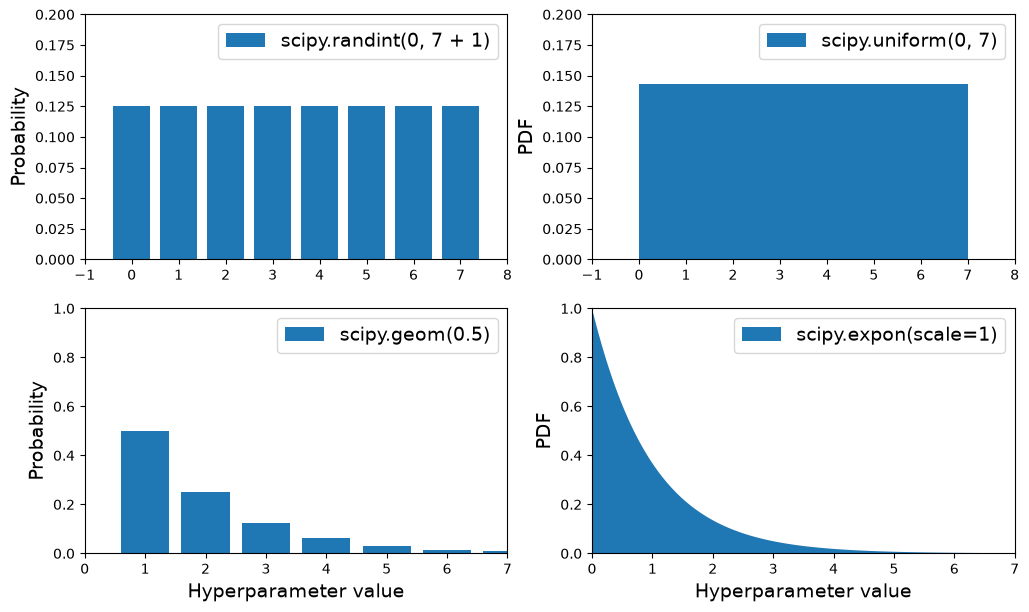

In [ ]:
# extra code – plots a few distributions you can use in randomized search

from scipy.stats import randint, uniform, geom, expon

xs1 = np.arange(0, 7 + 1)
randint_distrib = randint(0, 7 + 1).pmf(xs1)

xs2 = np.linspace(0, 7, 500)
uniform_distrib = uniform(0, 7).pdf(xs2)

xs3 = np.arange(0, 7 + 1)
geom_distrib = geom(0.5).pmf(xs3)

xs4 = np.linspace(0, 7, 500)
expon_distrib = expon(scale=1).pdf(xs4)

plt.figure(figsize=(12, 7))

plt.subplot(2, 2, 1)
plt.bar(xs1, randint_distrib, label="scipy.randint(0, 7 + 1)")
plt.ylabel("Probability")
plt.legend()
plt.axis([-1, 8, 0, 0.2])

plt.subplot(2, 2, 2)
plt.fill_between(xs2, uniform_distrib, label="scipy.uniform(0, 7)")
plt.ylabel("PDF")
plt.legend()
plt.axis([-1, 8, 0, 0.2])

plt.subplot(2, 2, 3)
plt.bar(xs3, geom_distrib, label="scipy.geom(0.5)")
plt.xlabel("Hyperparameter value")
plt.ylabel("Probability")
plt.legend()
plt.axis([0, 7, 0, 1])

plt.subplot(2, 2, 4)
plt.fill_between(xs4, expon_distrib, label="scipy.expon(scale=1)")
plt.xlabel("Hyperparameter value")
plt.ylabel("PDF")
plt.legend()
plt.axis([0, 7, 0, 1])

plt.show()

Aquí están las PDF para `expon()` y `loguniform()` (columna izquierda), así como la PDF de log(X) (columna derecha). La columna derecha muestra la distribución de las _escalas_ de los hiperparámetros. Podés ver que `expon()` favorece hiperparámetros con aproximadamente la escala deseada, con una cola más larga hacia las escalas más pequeñas. Pero `loguniform()` no favorece ninguna escala, todas son igualmente probables:

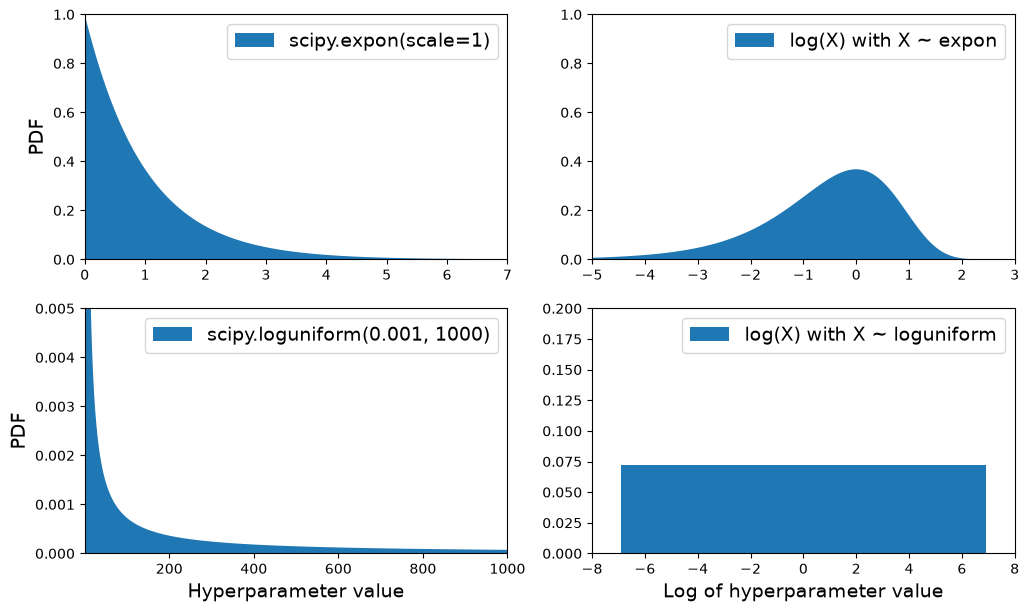

In [ ]:
# extra code – shows the difference between expon and loguniform

from scipy.stats import loguniform

xs1 = np.linspace(0, 7, 500)
expon_distrib = expon(scale=1).pdf(xs1)

log_xs2 = np.linspace(-5, 3, 500)
log_expon_distrib = np.exp(log_xs2 - np.exp(log_xs2))

xs3 = np.linspace(0.001, 1000, 500)
loguniform_distrib = loguniform(0.001, 1000).pdf(xs3)

log_xs4 = np.linspace(np.log(0.001), np.log(1000), 500)
log_loguniform_distrib = uniform(loc=np.log(0.001),
                                 scale=np.log(1000) - np.log(0.001)).pdf(log_xs4)

plt.figure(figsize=(12, 7))

plt.subplot(2, 2, 1)
plt.fill_between(xs1, expon_distrib,
                 label="scipy.expon(scale=1)")
plt.ylabel("PDF")
plt.legend()
plt.axis([0, 7, 0, 1])

plt.subplot(2, 2, 2)
plt.fill_between(log_xs2, log_expon_distrib,
                 label="log(X) with X ~ expon")
plt.legend()
plt.axis([-5, 3, 0, 1])

plt.subplot(2, 2, 3)
plt.fill_between(xs3, loguniform_distrib,
                 label="scipy.loguniform(0.001, 1000)")
plt.xlabel("Hyperparameter value")
plt.ylabel("PDF")
plt.legend()
plt.axis([0.001, 1000, 0, 0.005])

plt.subplot(2, 2, 4)
plt.fill_between(log_xs4, log_loguniform_distrib,
                 label="log(X) with X ~ loguniform")
plt.xlabel("Log of hyperparameter value")
plt.legend()
plt.axis([-8, 8, 0, 0.2])

plt.show()

## Analizar los mejores modelos y sus errores

In [ ]:
final_model = rnd_search.best_estimator_  # includes preprocessing
feature_importances = final_model["random_forest"].feature_importances_
feature_importances.round(2)

array([0.06, 0.05, 0.06, 0.01, 0.01, 0.01, 0.01, 0.17, 0.01, 0.01, 0.01,
       0.02, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.  , 0.  , 0.01, 0.03,
       0.01, 0.01, 0.02, 0.01, 0.  , 0.01, 0.01, 0.01, 0.01, 0.01, 0.03,
       0.01, 0.01, 0.01, 0.02, 0.01, 0.01, 0.01, 0.01, 0.01, 0.03, 0.04,
       0.01, 0.01, 0.01, 0.01, 0.01, 0.  , 0.01, 0.01, 0.02, 0.  , 0.07,
       0.  , 0.  , 0.  , 0.01])

In [ ]:
sorted(zip(feature_importances,
           final_model["preprocessing"].get_feature_names_out()),
           reverse=True)

[(np.float64(0.1735454119679924), 'log__median_income'),
 (np.float64(0.06788378064362875), 'cat__ocean_proximity_INLAND'),
 (np.float64(0.06284306674308061), 'bedrooms__ratio'),
 (np.float64(0.057266721148780675), 'people_per_house__ratio'),
 (np.float64(0.047938255005602184), 'rooms_per_house__ratio'),
 (np.float64(0.03605973265373645), 'geo__Cluster 35 similarity'),
 (np.float64(0.02740298239593355), 'geo__Cluster 34 similarity'),
 (np.float64(0.026558025819255482), 'geo__Cluster 24 similarity'),
 (np.float64(0.025564900634172147), 'geo__Cluster 13 similarity'),
 (np.float64(0.020614857261579946), 'geo__Cluster 3 similarity'),
 (np.float64(0.01995233933371085), 'geo__Cluster 16 similarity'),
 (np.float64(0.018806465147058173), 'geo__Cluster 28 similarity'),
 (np.float64(0.018804689229477648), 'geo__Cluster 44 similarity'),
 (np.float64(0.014808624496688858), 'geo__Cluster 30 similarity'),
 (np.float64(0.013952583807453112), 'geo__Cluster 14 similarity'),
 (np.float64(0.0136068751610

## Evaluar tu sistema sobre el conjunto de prueba (test set)

**⚠️ Error común — Usar el conjunto de prueba antes de la evaluación final**

El test set se toca **una sola vez**, al final, para estimar el desempeño real del modelo elegido. Errores frecuentes:

- **Ajustar hiperparámetros mirando el test** → el número final ya no es una estimación honesta de generalización (optimizaste contra él).
- **Ajustar transformadores (imputador, scaler, encoder) con datos que incluyen el test** → *data leakage*: información del test se filtra al entrenamiento. Por eso todo el preprocesamiento va dentro del `Pipeline` y se hace `fit` solo con el train.
- **Volver a tocar features o el modelo después de ver el resultado del test** → convierte al test, de hecho, en otro set de validación.

Notá en la celda que `final_model` solo hace `transform` (no `fit`) sobre `X_test`, y que todo el tuning se hizo antes con validación cruzada sobre el train.

In [ ]:
X_test = strat_test_set.drop("median_house_value", axis=1)
y_test = strat_test_set["median_house_value"].copy()

final_predictions = final_model.predict(X_test)

final_rmse = root_mean_squared_error(y_test, final_predictions)
print(final_rmse)

42537.741264526725


Podemos calcular un intervalo de confianza del 95% para el RMSE de prueba:

In [ ]:
from scipy import stats

def rmse(squared_errors):
    return np.sqrt(np.mean(squared_errors))

confidence = 0.95
squared_errors = (final_predictions - y_test) ** 2
boot_result = stats.bootstrap([squared_errors], rmse,
                              confidence_level=confidence, random_state=42)
rmse_lower, rmse_upper = boot_result.confidence_interval


**📘 Explicación adicional — Intervalo de confianza del RMSE**

El RMSE sobre el test es **una estimación puntual**: si el test hubiera sido otro, el número variaría un poco. Un intervalo de confianza del 95% nos dice un rango dentro del cual esperamos que caiga el verdadero error de generalización.

La celda lo calcula a partir de los **errores al cuadrado** de cada predicción usando la distribución $t$ de Student (`scipy.stats`), y luego toma raíz cuadrada para volver a unidades de RMSE. La idea intuitiva:

$$\text{IC}_{95\%} \;=\; \sqrt{\;\text{intervalo del }95\%\text{ sobre la media de los errores}^2\;}$$

**Por qué importa en un proyecto real:** reportar "RMSE = 41.500" es incompleto; reportar "RMSE ≈ 41.500, IC 95% [39.300, 43.700]" comunica la **incertidumbre** de la estimación. Con un test chico el intervalo será ancho, señal de que el número puntual no es tan confiable.

In [ ]:
rmse_lower, rmse_upper

(np.float64(40608.16222664642), np.float64(44794.79070629331))

## Persistencia del modelo usando joblib

Guardamos el modelo final:

In [ ]:
import joblib

joblib.dump(final_model, "my_california_housing_model.pkl")

['my_california_housing_model.pkl']

Ahora podés desplegar (deploy) este modelo en producción. Por ejemplo, el siguiente código podría ser un script que se ejecutaría en producción:

In [ ]:
import joblib

# extra code – excluded for conciseness
from sklearn.cluster import KMeans
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics.pairwise import rbf_kernel

def column_ratio(X):
    return X[:, [0]] / X[:, [1]]

def ratio_name(function_transformer, feature_names_in):
    return ["ratio"]

#class ClusterSimilarity(BaseEstimator, TransformerMixin):
#    [...]

final_model_reloaded = joblib.load("my_california_housing_model.pkl")

new_data = housing.iloc[:5]  # pretend these are new districts
predictions = final_model_reloaded.predict(new_data)

In [ ]:
predictions

array([461235.08, 108850.  , 101274.  , 338081.02, 104453.  ])

Podrías usar pickle en su lugar, pero joblib es más eficiente.

**💼 ¿Qué utilizaría en un proyecto real? — Persistencia y despliegue del modelo**

1. **Elección recomendada:** `joblib` para serializar estimadores de Scikit-Learn (maneja mejor los arrays NumPy grandes que `pickle`). Se guarda el **pipeline completo** (preprocesamiento + modelo), no solo el estimador final.
2. **Uso en la industria:** `joblib`/`pickle` para el artefacto; además se usan formatos/registros como **MLflow Model Registry**, ONNX (para interoperabilidad) o contenedores Docker que exponen el modelo vía API.
3. **Criterios de decisión:** tamaño del modelo, necesidad de interoperabilidad entre lenguajes, y requisitos de latencia.
4. **Ejemplo laboral:** un microservicio FastAPI carga `my_california_housing_model.pkl` al iniciar y responde predicciones; CI/CD reemplaza el `.pkl` cuando se reentrena.
5. **Buenas prácticas (críticas):** **fijar la versión de las librerías** (un `.pkl` puede no cargar con otra versión de Scikit-Learn), **versionar el artefacto** junto a los datos y el código que lo generaron (reproducibilidad), y validar que las features de entrada en producción coincidan con las de entrenamiento. Cuidado: deserializar un `pickle` de origen no confiable es un riesgo de seguridad.
6. **Qué debería recordar:** guardo el pipeline entero con `joblib`, congelo versiones y versiono el artefacto; para entornos políglotas o grandes, evalúo ONNX o un registro de modelos.

# Soluciones de los ejercicios

## 1.

Ejercicio: _Probá un regresor de Máquinas de Vectores de Soporte (`sklearn.svm.SVR`) con varios hiperparámetros, como `kernel="linear"` (con distintos valores para el hiperparámetro `C`) o `kernel="rbf"` (con distintos valores para los hiperparámetros `C` y `gamma`). Notá que las SVM no escalan bien a datasets grandes, así que probablemente debieras entrenar tu modelo solo con las primeras 5.000 instancias del conjunto de entrenamiento y usar únicamente validación cruzada de 3 pliegues (3-fold), o de lo contrario llevará horas. No te preocupes por ahora respecto de qué significan los hiperparámetros (ver el notebook de SVM si te interesa). ¿Cómo se desempeña el mejor predictor `SVR`?_

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVR

param_grid = [
        {'svr__kernel': ['linear'], 'svr__C': [10., 30., 100., 300., 1000.,
                                               3000., 10000., 30000.0]},
        {'svr__kernel': ['rbf'], 'svr__C': [1.0, 3.0, 10., 30., 100., 300.,
                                            1000.0],
         'svr__gamma': [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]},
    ]

svr_pipeline = Pipeline([("preprocessing", preprocessing), ("svr", SVR())])
grid_search = GridSearchCV(svr_pipeline, param_grid, cv=3,
                           scoring='neg_root_mean_squared_error')
grid_search.fit(housing.iloc[:5000], housing_labels.iloc[:5000])

El mejor modelo alcanza el siguiente puntaje (evaluado usando validación cruzada de 3 pliegues):

In [ ]:
svr_grid_search_rmse = -grid_search.best_score_
svr_grid_search_rmse

np.float64(68379.38577166256)

Eso es mucho peor que el `RandomForestRegressor` (aunque, para ser justos, entrenamos el modelo con muchos menos datos). Verifiquemos los mejores hiperparámetros encontrados:

In [ ]:
grid_search.best_params_

{'svr__C': 10000.0, 'svr__kernel': 'linear'}

El kernel lineal parece mejor que el kernel RBF. Notá que el valor de `C` es el valor máximo probado. Cuando esto ocurre, definitivamente conviene relanzar la búsqueda en grilla con valores más altos de `C` (quitando los valores más pequeños), porque es probable que valores más altos de `C` sean mejores.

## 2.

Ejercicio: _Probá reemplazar el `GridSearchCV` por un `RandomizedSearchCV`._

**Advertencia:** la siguiente celda tardará varios minutos en ejecutarse. Podés especificar `verbose=2` al crear el `RandomizedSearchCV` si querés ver los detalles del entrenamiento.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import expon, loguniform

# see https://docs.scipy.org/doc/scipy/reference/stats.html
# for `expon()` and `loguniform()` documentation and more probability distribution functions.

# Note: gamma is ignored when kernel is "linear"
param_distribs = {
        'svr__kernel': ['linear', 'rbf'],
        'svr__C': loguniform(20, 200_000),
        'svr__gamma': expon(scale=1.0),
    }

rnd_search = RandomizedSearchCV(svr_pipeline,
                                param_distributions=param_distribs,
                                n_iter=50, cv=3,
                                scoring='neg_root_mean_squared_error',
                                random_state=42)
rnd_search.fit(housing.iloc[:5000], housing_labels.iloc[:5000])

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...svr', SVR())])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'svr__C': <scipy.stats....002987F2533B0>, 'svr__gamma': <scipy.stats....002987F47EB10>, 'svr__kernel': ['linear', 'rbf']}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` i

El mejor modelo alcanza el siguiente puntaje (evaluado usando validación cruzada de 3 pliegues):

In [ ]:
svr_rnd_search_rmse = -rnd_search.best_score_
svr_rnd_search_rmse

np.float64(55053.06019834047)

Ahora sí es mucho mejor, pero todavía lejos del desempeño del `RandomForestRegressor`. Verifiquemos los mejores hiperparámetros encontrados:

In [ ]:
rnd_search.best_params_

{'svr__C': np.float64(157055.10989448498),
 'svr__gamma': np.float64(0.26497040005002437),
 'svr__kernel': 'rbf'}

Esta vez la búsqueda encontró un buen conjunto de hiperparámetros para el kernel RBF. La búsqueda aleatoria tiende a encontrar mejores hiperparámetros que la búsqueda en grilla en la misma cantidad de tiempo.

Notá que usamos la distribución `expon()` para `gamma`, con una escala (scale) de 1, por lo que `RandomSearch` buscó mayormente valores de aproximadamente esa escala: cerca del 80% de las muestras estuvieron entre 0.1 y 2.3 (aproximadamente un 10% fueron menores y un 10% mayores):

In [ ]:
np.random.seed(42)

s = expon(scale=1).rvs(100_000)  # get 100,000 samples
((s > 0.105) & (s < 2.29)).sum() / 100_000

np.float64(0.80066)

Usamos la distribución `loguniform()` para `C`, lo que significa que no teníamos idea de cuál era la escala óptima de `C` antes de ejecutar la búsqueda aleatoria. Exploró el rango de 20 a 200 tanto como el rango de 2.000 a 20.000 o de 20.000 a 200.000.

## 3.

Ejercicio: _Probá agregar un transformador `SelectFromModel` en el pipeline de preparación para seleccionar únicamente los atributos más importantes._

Creemos un nuevo pipeline que ejecute el pipeline de preparación definido previamente, y agregue un transformador `SelectFromModel` basado en un `RandomForestRegressor` antes del regresor final:

In [ ]:
from sklearn.feature_selection import SelectFromModel

selector_pipeline = Pipeline([
    ('preprocessing', preprocessing),
    ('selector', SelectFromModel(RandomForestRegressor(random_state=42),
                                 threshold=0.005)),  # min feature importance
    ('svr', SVR(C=rnd_search.best_params_["svr__C"],
                gamma=rnd_search.best_params_["svr__gamma"],
                kernel=rnd_search.best_params_["svr__kernel"])),
])

In [ ]:
selector_rmses = -cross_val_score(selector_pipeline,
                                  housing.iloc[:5000],
                                  housing_labels.iloc[:5000],
                                  scoring="neg_root_mean_squared_error",
                                  cv=3)
pd.Series(selector_rmses).describe()

count        3.000000
mean     55392.006810
std       2290.497463
min      53430.579600
25%      54133.375789
50%      54836.171978
75%      56372.720415
max      57909.268853
dtype: float64

Bueno, la selección de características no parece ayudar. Pero quizás sea simplemente porque el umbral (threshold) que usamos no era óptimo. ¿Tal vez convenga ajustarlo usando búsqueda aleatoria o en grilla?

## 4.

Ejercicio: _Probá crear un transformador personalizado que entrene un regresor de k-vecinos más cercanos (`sklearn.neighbors.KNeighborsRegressor`) en su método `fit()`, y produzca las predicciones del modelo en su método `transform()`. Luego agregá esta característica al pipeline de preprocesamiento, usando la latitud y la longitud como entradas de este transformador. Esto agregará al modelo una característica que corresponde al precio mediano de las viviendas de los distritos más cercanos._

En lugar de restringirnos a los regresores de k-vecinos más cercanos, creemos un transformador que acepte cualquier regresor. Para esto, podemos extender `MetaEstimatorMixin` y tener un argumento `estimator` obligatorio en el constructor. El método `fit()` debe trabajar sobre un clon (clone) de este estimador, y también debe guardar `feature_names_in_`. `MetaEstimatorMixin` se asegurará de que `estimator` figure como un parámetro obligatorio, y actualizará `get_params()` y `set_params()` para hacer que los hiperparámetros del estimador estén disponibles para el ajuste. Por último, creamos un método `get_feature_names_out()`: el nombre de la columna de salida es el ...

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.base import MetaEstimatorMixin, clone
from sklearn.utils.validation import check_array

class FeatureFromRegressor(MetaEstimatorMixin, TransformerMixin, BaseEstimator):
    def __init__(self, estimator):
        self.estimator = estimator

    def fit(self, X, y=None):
        check_array(X)
        self.estimator_ = clone(self.estimator)
        self.estimator_.fit(X, y)
        self.n_features_in_ = self.estimator_.n_features_in_
        if hasattr(self.estimator_, "feature_names_in_"):
            self.feature_names_in_ = self.estimator_.feature_names_in_
        return self  # always return self!
    
    def transform(self, X):
        check_is_fitted(self)
        predictions = self.estimator_.predict(X)
        if predictions.ndim == 1:
            predictions = predictions.reshape(-1, 1)
        return predictions

    def get_feature_names_out(self, names=None):
        check_is_fitted(self)
        n_outputs = getattr(self.estimator_, "n_outputs_", 1)
        estimator_class_name = self.estimator_.__class__.__name__
        estimator_short_name = estimator_class_name.lower().replace("_", "")
        return [f"{estimator_short_name}_prediction_{i}"
                for i in range(n_outputs)]

Asegurémonos de que cumpla con la API de Scikit-Learn:

In [ ]:
from sklearn.utils.estimator_checks import check_estimator

test_results = check_estimator(FeatureFromRegressor(KNeighborsRegressor()))

c:\Users\famil\Desktop\IA LUCAS\VALP\VALP_UTN\.venv\Lib\site-packages\sklearn\utils\estimator_checks.py:919: SkipTestWarning: Skipping check check_array_api_input for FeatureFromRegressor because it raised SkipTest: SCIPY_ARRAY_API is not set: not checking array_api input
  warnings.warn(


¡Bien! Ahora probémoslo:

In [ ]:
knn_reg = KNeighborsRegressor(n_neighbors=3, weights="distance")
knn_transformer = FeatureFromRegressor(knn_reg)
geo_features = housing[["latitude", "longitude"]]
knn_transformer.fit_transform(geo_features, housing_labels)

array([[435250.        ],
       [101400.        ],
       [ 96100.        ],
       ...,
       [148800.        ],
       [500001.        ],
       [234333.33333333]], shape=(14448, 1))

¿Y cómo luce el nombre de su característica de salida?

In [ ]:
knn_transformer.get_feature_names_out()

['kneighborsregressor_prediction_0']

Bien, ahora incluyamos este transformador en nuestro pipeline de preprocesamiento:

In [ ]:
from sklearn.base import clone

transformers = [(name, clone(transformer), columns)
                for name, transformer, columns in preprocessing.transformers]
geo_index = [name for name, _, _ in transformers].index("geo")
transformers[geo_index] = ("geo", knn_transformer, ["latitude", "longitude"])

new_geo_preprocessing = ColumnTransformer(transformers)

In [ ]:
new_geo_pipeline = Pipeline([
    ('preprocessing', new_geo_preprocessing),
    ('svr', SVR(C=rnd_search.best_params_["svr__C"],
                gamma=rnd_search.best_params_["svr__gamma"],
                kernel=rnd_search.best_params_["svr__kernel"])),
])

In [ ]:
new_pipe_rmses = -cross_val_score(new_geo_pipeline,
                                  housing.iloc[:5000],
                                  housing_labels.iloc[:5000],
                                  scoring="neg_root_mean_squared_error",
                                  cv=3)
pd.Series(new_pipe_rmses).describe()

count         3.000000
mean     103011.516347
std        1483.687247
min      102076.675009
25%      102156.138577
50%      102235.602145
75%      103478.937016
max      104722.271887
dtype: float64

¡Uf, qué desastre! Aparentemente las características de similitud por clusters (cluster similarity) eran mucho mejores. Pero quizás deberíamos ajustar los hiperparámetros del `KNeighborsRegressor`. De eso trata el próximo ejercicio.

## 5.

Ejercicio: _Explorá automáticamente algunas opciones de preparación usando `RandomSearchCV`._

In [ ]:
param_distribs = {
    "preprocessing__geo__estimator__n_neighbors": range(1, 30),
    "preprocessing__geo__estimator__weights": ["distance", "uniform"],
    "svr__C": loguniform(20, 200_000),
    "svr__gamma": expon(scale=1.0),
}

new_geo_rnd_search = RandomizedSearchCV(new_geo_pipeline,
                                        param_distributions=param_distribs,
                                        n_iter=50,
                                        cv=3,
                                        scoring='neg_root_mean_squared_error',
                                        random_state=42)
new_geo_rnd_search.fit(housing.iloc[:5000], housing_labels.iloc[:5000])

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...005002437)))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'preprocessing__geo__estimator__n_neighbors': range(1, 30), 'preprocessing__geo__estimator__weights': ['distance', 'uniform'], 'svr__C': <scipy.stats....002987C272930>, 'svr__gamma': <scipy.stats....002987C2710A0>}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_e

In [ ]:
new_geo_rnd_search_rmse = -new_geo_rnd_search.best_score_
new_geo_rnd_search_rmse

np.float64(102832.00328105521)

Bueno... ¡al menos lo intentamos! Parece que las características de similitud por clusters son definitivamente mejores que la característica de KNN. Pero quizás podrías probar teniendo ambas. Y tal vez entrenar sobre el conjunto de entrenamiento completo también ayudaría.

## 6.

Ejercicio: _Intentá implementar nuevamente la clase `StandardScalerClone` desde cero, y luego agregá soporte para el método `inverse_transform()`: ejecutar `scaler.inverse_transform(scaler.fit_transform(X))` debería devolver un array muy cercano a `X`. Después agregá soporte para los nombres de características: establecé <code>feature_names_in&#95;</code> en el método `fit()` si la entrada es un DataFrame. Este atributo debe ser un array de NumPy con los nombres de las columnas. Por último, implementá el método `get_feature_names_out()`: debe tener un argumento opcional `input_features=None`. Si se lo pasa, el método debe verificar que su longitud coincida con <code>n_features_in&#95;</code>, y debe coincidir con <code>feature_names_in&#95;</code> si está definido; entonces debe devolverse `input_features`. Si `input_features` es `None`, entonces el método debe devolver <code>feature_names_in&#95;</code> si está definido, o `np.array(["x0", "x1", ...])` con longitud <code>n_features_in&#95;</code> en caso contrario._

In [ ]:
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted

try:
    from sklearn.utils.validation import validate_data
except ImportError:  # Scikit-Learn < 1.6
    def validate_data(estimator, X, **kwargs):
        return estimator._validate_data(X, **kwargs)

class StandardScalerClone(TransformerMixin, BaseEstimator):
    def __init__(self, with_mean=True):  # no *args or **kwargs!
        self.with_mean = with_mean

    def fit(self, X, y=None):
        X = validate_data(self, X, ensure_2d=True)
        self.n_features_in_ = X.shape[1]
        if self.with_mean:
            self.mean_ = np.mean(X, axis=0)
        self.scale_ = np.std(X, axis=0, ddof=0)
        self.scale_[self.scale_ == 0] = 1  # Avoid division by zero
        return self
    
    def transform(self, X):
        check_is_fitted(self)
        X = validate_data(self, X, ensure_2d=True, reset=False)
        if self.with_mean:
            X = X - self.mean_
        return X / self.scale_
    
    def inverse_transform(self, X):
        check_is_fitted(self)
        X = validate_data(self, X, ensure_2d=True, reset=False)
        X = X * self.scale_
        if self.with_mean:
            X = X + self.mean_
        return X

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            return getattr(self, "feature_names_in_",
                           [f"x{i}" for i in range(self.n_features_in_)])
        else:
            if len(input_features) != self.n_features_in_:
                raise ValueError("Invalid number of features")
            if hasattr(self, "feature_names_in_") and not np.all(
                self.feature_names_in_ == input_features
            ):
                raise ValueError("input_features ≠ feature_names_in_")
            return input_features

Probemos nuestro transformador personalizado:

In [ ]:
from sklearn.utils.estimator_checks import check_estimator
 
check_estimator(StandardScalerClone())

c:\Users\famil\Desktop\IA LUCAS\VALP\VALP_UTN\.venv\Lib\site-packages\sklearn\utils\estimator_checks.py:919: SkipTestWarning: Skipping check check_array_api_input for StandardScalerClone because it raised SkipTest: SCIPY_ARRAY_API is not set: not checking array_api input
  warnings.warn(


[{'estimator': StandardScalerClone(),
  'check_name': 'check_estimator_cloneable',
  'exception': None,
  'status': 'passed',
  'expected_to_fail': False,
  'expected_to_fail_reason': 'Check is not expected to fail'},
 {'estimator': StandardScalerClone(),
  'check_name': 'check_estimator_tags_renamed',
  'exception': None,
  'status': 'passed',
  'expected_to_fail': False,
  'expected_to_fail_reason': 'Check is not expected to fail'},
 {'estimator': StandardScalerClone(),
  'check_name': 'check_valid_tag_types',
  'exception': None,
  'status': 'passed',
  'expected_to_fail': False,
  'expected_to_fail_reason': 'Check is not expected to fail'},
 {'estimator': StandardScalerClone(),
  'check_name': 'check_estimator_repr',
  'exception': None,
  'status': 'passed',
  'expected_to_fail': False,
  'expected_to_fail_reason': 'Check is not expected to fail'},
 {'estimator': StandardScalerClone(),
  'check_name': 'check_no_attributes_set_in_init',
  'exception': None,
  'status': 'passed',
  

Sin errores, es un gran comienzo: respetamos la API de Scikit-Learn.

Ahora asegurémonos de que la transformación funcione como se espera:

In [ ]:
np.random.seed(42)
X = np.random.rand(1000, 3)

scaler = StandardScalerClone()
X_scaled = scaler.fit_transform(X)

assert np.allclose(X_scaled, (X - X.mean(axis=0)) / X.std(axis=0))

¿Y si establecemos `with_mean=False`?

In [ ]:
scaler = StandardScalerClone(with_mean=False)
X_scaled_uncentered = scaler.fit_transform(X)

assert np.allclose(X_scaled_uncentered, X / X.std(axis=0))

¿Y funciona la inversa?

In [ ]:
scaler = StandardScalerClone()
X_back = scaler.inverse_transform(scaler.fit_transform(X))

assert np.allclose(X, X_back)

¿Qué tal los nombres de las características de salida (feature names out)?

In [ ]:
assert np.all(scaler.get_feature_names_out() == ["x0", "x1", "x2"])
assert np.all(scaler.get_feature_names_out(["a", "b", "c"]) == ["a", "b", "c"])

Y si ajustamos (fit) un DataFrame, ¿están bien las características de entrada y de salida?

In [ ]:
df = pd.DataFrame({"a": np.random.rand(100), "b": np.random.rand(100)})
scaler = StandardScalerClone()
X_scaled = scaler.fit_transform(df)

assert np.all(scaler.feature_names_in_ == ["a", "b"])
assert np.all(scaler.get_feature_names_out() == ["a", "b"])

¡Todo bien! ¡Eso es todo por hoy! 😀

¡Felicitaciones! Ya sabés bastante sobre Machine Learning. :)